[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/isocan/ML-accelerated-ORR/blob/main/notebooks/03_stageI_eqv2_adsorption_site_analysis.ipynb)

# Stage I: analysis of EqV2 adsorption energies and adsorption-site families

This notebook continues
[`02_stageI_eqv2_trajectory_screening.ipynb`](02_stageI_eqv2_trajectory_screening.ipynb). It analyzes
the OC20/EquiformerV2 (EqV2) predicted adsorption energies of O$^{*}$, OH$^{*}$, and
OOH$^{*}$ using the site-family minima written by the screening notebook. Each row of
that table is the lowest-energy validated configuration of one site family (site motif
and coordinating elements) within one slab–adsorbate system. The library contains the
555 bimetallic surfaces and the Pt(111) reference surface (`mp-126_111`).

**Figures S1 and S2** are Supporting Information figures of the article. The remaining
figures are descriptive statistics of the same data, provided for readers who want to
explore the site-resolved ML landscape. They are not part of the article.

| Section | Output (in `figures/stageI_eqv2/`) |
|---|---|
| Energy window | `energy_window_summary.csv`, `excluded_site_family_minima.csv` |
| Figure S1: adsorption-energy distributions | `Figure_S1.pdf/.svg/.png` |
| Figure S2: adsorption-site preferences | `Figure_S2.pdf/.svg/.png`, `Figure_S2_*.csv` |
| Contacting elements and adsorption energies | `contact_elements.*`, `contact_elements_source_data.csv` |
| Radar profiles of adsorption-site motifs | `site_motif_radar.*`, `site_motif_radar_source_data.csv`, `site_motif_reassignments.csv` |
| O$^{*}$ energy by site motif and element | `oxygen_adsorption_by_site_motif.*` and source data |
| O$^{*}$ energy versus electronegativity | `oxygen_adsorption_vs_electronegativity.*` and source data |
| Distributions by contacting element | `adsorption_energy_ridgelines.*` and source data |

Every figure is saved as PDF and SVG (editable vector) and as a 600 dpi PNG, together
with a CSV of the plotted values.

## Input

The notebook reads `orr_eqv2_adsorption_site_family_minima.csv` from
`data/stageI_eqv2/processed/`. It uses the CSV if the screening notebook has written it
there, and otherwise reads it from `orr_eqv2_stageI_tables.zip` in the same folder,
which is committed to the repository. If neither is present (for example in Colab
without a clone), it downloads the ZIP from GitHub. The trajectories are not needed.

Main columns used: `predicted_adsorption_energy_eV` (EqV2 adsorption energy),
`relative_energy_within_system_eV` (energy above the lowest validated configuration of
the same system), `site_type`, `site_family`, `coordination`, `binding_oxygen_index`,
and `oxygen_contacts_json` (first-shell O–slab contacts of each oxygen).

## Adsorption-energy window

All figures use one common window, $-7 \le E_{\mathrm{ads}}^{\mathrm{EqV2}} \le +7$ eV,
with both endpoints included. A common window keeps the plotted populations and
denominators consistent across figures and limits the influence of the sparse
high-energy tail on mean-based summaries. It is a descriptive choice applied after
trajectory and site screening.

Of the 6,131 site-family minima, the window retains 6,128 and excludes 3 (0.049%).
All three lie above +7 eV: two O$^{*}$ minima on `mp-786_100_O` (+10.87 and +11.55 eV)
and one OOH$^{*}$ minimum on `mp-786_111_OOH` (+10.70 eV), both MnSb surfaces. These
are the only site-family minima of those two systems. The two tables in the next cell
list the exclusions.

## Software environment

The figures were produced with the environment of the screening notebook. Only the
following packages are needed here:

```bash
python -m pip install jupyterlab "matplotlib>=3.8" numpy pandas scipy
```

Run all cells from top to bottom, from the repository root or from `notebooks/`.

In [1]:
from itertools import combinations
import json
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile
from urllib.error import HTTPError, URLError
from urllib.request import urlopen

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.spatial import ConvexHull, QhullError

# Locate the repository root whether Jupyter starts at the root or in notebooks/.
working_dir = Path.cwd()
REPO_ROOT = next(
    (folder for folder in (working_dir, *working_dir.parents)
     if (folder / "data" / "stageI_eqv2").is_dir() or (folder / ".git").exists()),
    working_dir,
)
DEFAULT_DATA_DIR = Path("data/stageI_eqv2/processed")
# Folder with the screening tables written by 02_stageI_eqv2_trajectory_screening.ipynb.
DATA_DIR = REPO_ROOT / DEFAULT_DATA_DIR
DATA_FILE = "orr_eqv2_adsorption_site_family_minima.csv"
TABLES_ZIP = "orr_eqv2_stageI_tables.zip"
GITHUB_ZIP = (
    "https://raw.githubusercontent.com/isocan/ML-accelerated-ORR/main/"
    f"{DEFAULT_DATA_DIR.as_posix()}/{TABLES_ZIP}"
)


def read_site_family_minima():
    """Read the screening table from the CSV, the repository ZIP, or GitHub."""
    folder = Path(DATA_DIR).expanduser()
    csv_path, zip_path = folder / DATA_FILE, folder / TABLES_ZIP
    if csv_path.is_file():
        source, table = csv_path, pd.read_csv(csv_path)
    elif zip_path.is_file():
        with ZipFile(zip_path) as archive, archive.open(DATA_FILE) as handle:
            source, table = zip_path, pd.read_csv(handle)
    else:
        try:
            with urlopen(GITHUB_ZIP, timeout=60) as response:
                payload = BytesIO(response.read())
        except (HTTPError, URLError) as exc:
            raise FileNotFoundError(
                f"Could not find {DATA_FILE} or {TABLES_ZIP} in {folder}, or download "
                f"{GITHUB_ZIP}. Run 02_stageI_eqv2_trajectory_screening.ipynb first, "
                "or set DATA_DIR to the folder that contains the tables."
            ) from exc
        with ZipFile(payload) as archive, archive.open(DATA_FILE) as handle:
            source, table = GITHUB_ZIP, pd.read_csv(handle)
    shown = source.relative_to(REPO_ROOT) if isinstance(source, Path) and source.is_relative_to(REPO_ROOT) else source
    print(f"Site-family input: {shown}")
    return table


OUTPUT_DIR = REPO_ROOT / "figures" / "stageI_eqv2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ADSORBATES = ["O", "OH", "OOH"]
ENERGY_WINDOW = (-7.0, 7.0)
ENERGY = "predicted_adsorption_energy_eV"
SYSTEM_DELTA = "relative_energy_within_system_eV"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.65, "pdf.fonttype": 42, "svg.fonttype": "none",
})


def export_figure(fig, name):
    """Save editable vector artwork and a 600 dpi PNG, then show the PNG."""
    for extension in ("pdf", "svg", "png"):
        fig.savefig(OUTPUT_DIR / f"{name}.{extension}", dpi=600)
    plt.close(fig)
    display(Image(filename=str(OUTPUT_DIR / f"{name}.png"), width=960))

In [2]:
all_minima = read_site_family_minima()
REQUIRED_COLUMNS = [
    "system_id", "adsorbate", "site_family", "site_type", "coordination",
    "binding_oxygen_index", "oxygen_contacts_json", "unique_site_key",
    "trajectory_relative_path", ENERGY, SYSTEM_DELTA,
]
missing_columns = [column for column in REQUIRED_COLUMNS if column not in all_minima.columns]
if missing_columns:
    raise ValueError(
        f"{DATA_FILE} lacks {missing_columns}. Regenerate it with "
        "02_stageI_eqv2_trajectory_screening.ipynb."
    )
all_minima[ENERGY] = pd.to_numeric(all_minima[ENERGY], errors="raise")
if all_minima.duplicated(["system_id", "site_family"]).any():
    raise ValueError("Expected one minimum per slab–adsorbate system and site family.")
if set(all_minima["adsorbate"]) != set(ADSORBATES):
    raise ValueError("Expected site-family minima for O, OH, and OOH.")
if not np.isfinite(all_minima[[ENERGY, SYSTEM_DELTA]].to_numpy(dtype=float)).all():
    raise ValueError("The adsorption-energy columns must contain finite values.")
if all_minima[SYSTEM_DELTA].lt(-1e-8).any():
    raise ValueError("A relative energy falls below its validated system minimum.")

lower, upper = ENERGY_WINDOW
below = all_minima[ENERGY].lt(lower)
above = all_minima[ENERGY].gt(upper)
outside = below | above
minima = all_minima.loc[~outside].copy()
totals = minima.groupby("adsorbate").size().reindex(ADSORBATES, fill_value=0)

window_summary = (
    all_minima.assign(below_window=below, above_window=above)
    .groupby("adsorbate")
    .agg(initial_minima=(ENERGY, "size"), below_window=("below_window", "sum"),
         above_window=("above_window", "sum"))
    .reindex(ADSORBATES)
)
window_summary["excluded_minima"] = window_summary["below_window"] + window_summary["above_window"]
window_summary["retained_minima"] = totals
window_summary.loc["Total"] = window_summary.sum()
window_summary["excluded_pct"] = (
    100 * window_summary["excluded_minima"] / window_summary["initial_minima"]
)
window_summary.to_csv(OUTPUT_DIR / "energy_window_summary.csv")
display(window_summary.round({"excluded_pct": 3}))

columns = ["adsorbate", "system_id", "site_family", ENERGY, "trajectory_relative_path"]
excluded_minima = all_minima.loc[outside, columns].sort_values(["adsorbate", "system_id", ENERGY])
excluded_minima.to_csv(OUTPUT_DIR / "excluded_site_family_minima.csv", index=False)
display(excluded_minima.round({ENERGY: 6}))

missing_systems = sorted(set(all_minima["system_id"]) - set(minima["system_id"]))
print(f"Slab–adsorbate systems with every representative outside the window: {len(missing_systems)}")
if missing_systems:
    print(", ".join(missing_systems))


ELEMENT_GROUPS = {
    "3d": ["Ti", "Mn", "Fe", "Co", "Ni", "Cu"],
    "4d": ["Nb", "Mo", "Ru"],
    "5d": ["Ta", "Ir", "Pt"],
    "p block": ["Sn", "Sb"],
}
ELEMENTS = [element for group in ELEMENT_GROUPS.values() for element in group]


def contacting_elements(encoded_contacts):
    """Return distinct slab elements contacting either adsorbate oxygen."""
    return sorted({
        contact["symbol"]
        for shell in json.loads(encoded_contacts).values()
        for contact in shell
    })



element_contacts = minima.assign(
    element=minima["oxygen_contacts_json"].map(contacting_elements)
).explode("element")
if not element_contacts["element"].isin(ELEMENTS).all():
    raise ValueError("A contact is missing or falls outside the four element groups.")

Site-family input: data/stageI_eqv2/processed/orr_eqv2_stageI_tables.zip


,initial_minima,below_window,above_window,excluded_minima,retained_minima,excluded_pct
adsorbate,,,,,,
O,2740,0,2,2,2738,0.073
OH,2206,0,0,0,2206,0.000
OOH,1185,0,1,1,1184,0.084
Total,6131,0,3,3,6128,0.049


,adsorbate,system_id,site_family,predicted_adsorption_energy_eV,trajectory_relative_path
5293,O,mp-786_100_O,bridge__Mn-Mn,10.867188,mp-786_100_O/config_20.traj
5294,O,mp-786_100_O,4-fold__Mn-Mn-Mn-Mn,11.546875,mp-786_100_O/config_2.traj
5309,OOH,mp-786_111_OOH,top__Mn,10.703125,mp-786_111_OOH/config_27.traj


Slab–adsorbate systems with every representative outside the window: 2
mp-786_100_O, mp-786_111_OOH


## Figure S1. EqV2-predicted adsorption-energy distributions (Supporting Information)

Panels **a–c** show histograms for O*, OH*, and OOH*. Each inset reports the
mean, median, and number of site-family minima in the energy window. Panels
**d–f** show distributions by contacting slab element. Boxes span the
25th–75th percentiles and whiskers span the 5th–95th percentiles. Crosses mark
means, horizontal lines mark medians, and the vertical labels give the number
of minima containing each element. Each distinct contacting element contributes
one observation per site-family minimum, so a mixed-element site appears under each
of its elements. Tick labels are colored by element class: early, mid, and late
transition metals and p-block elements.

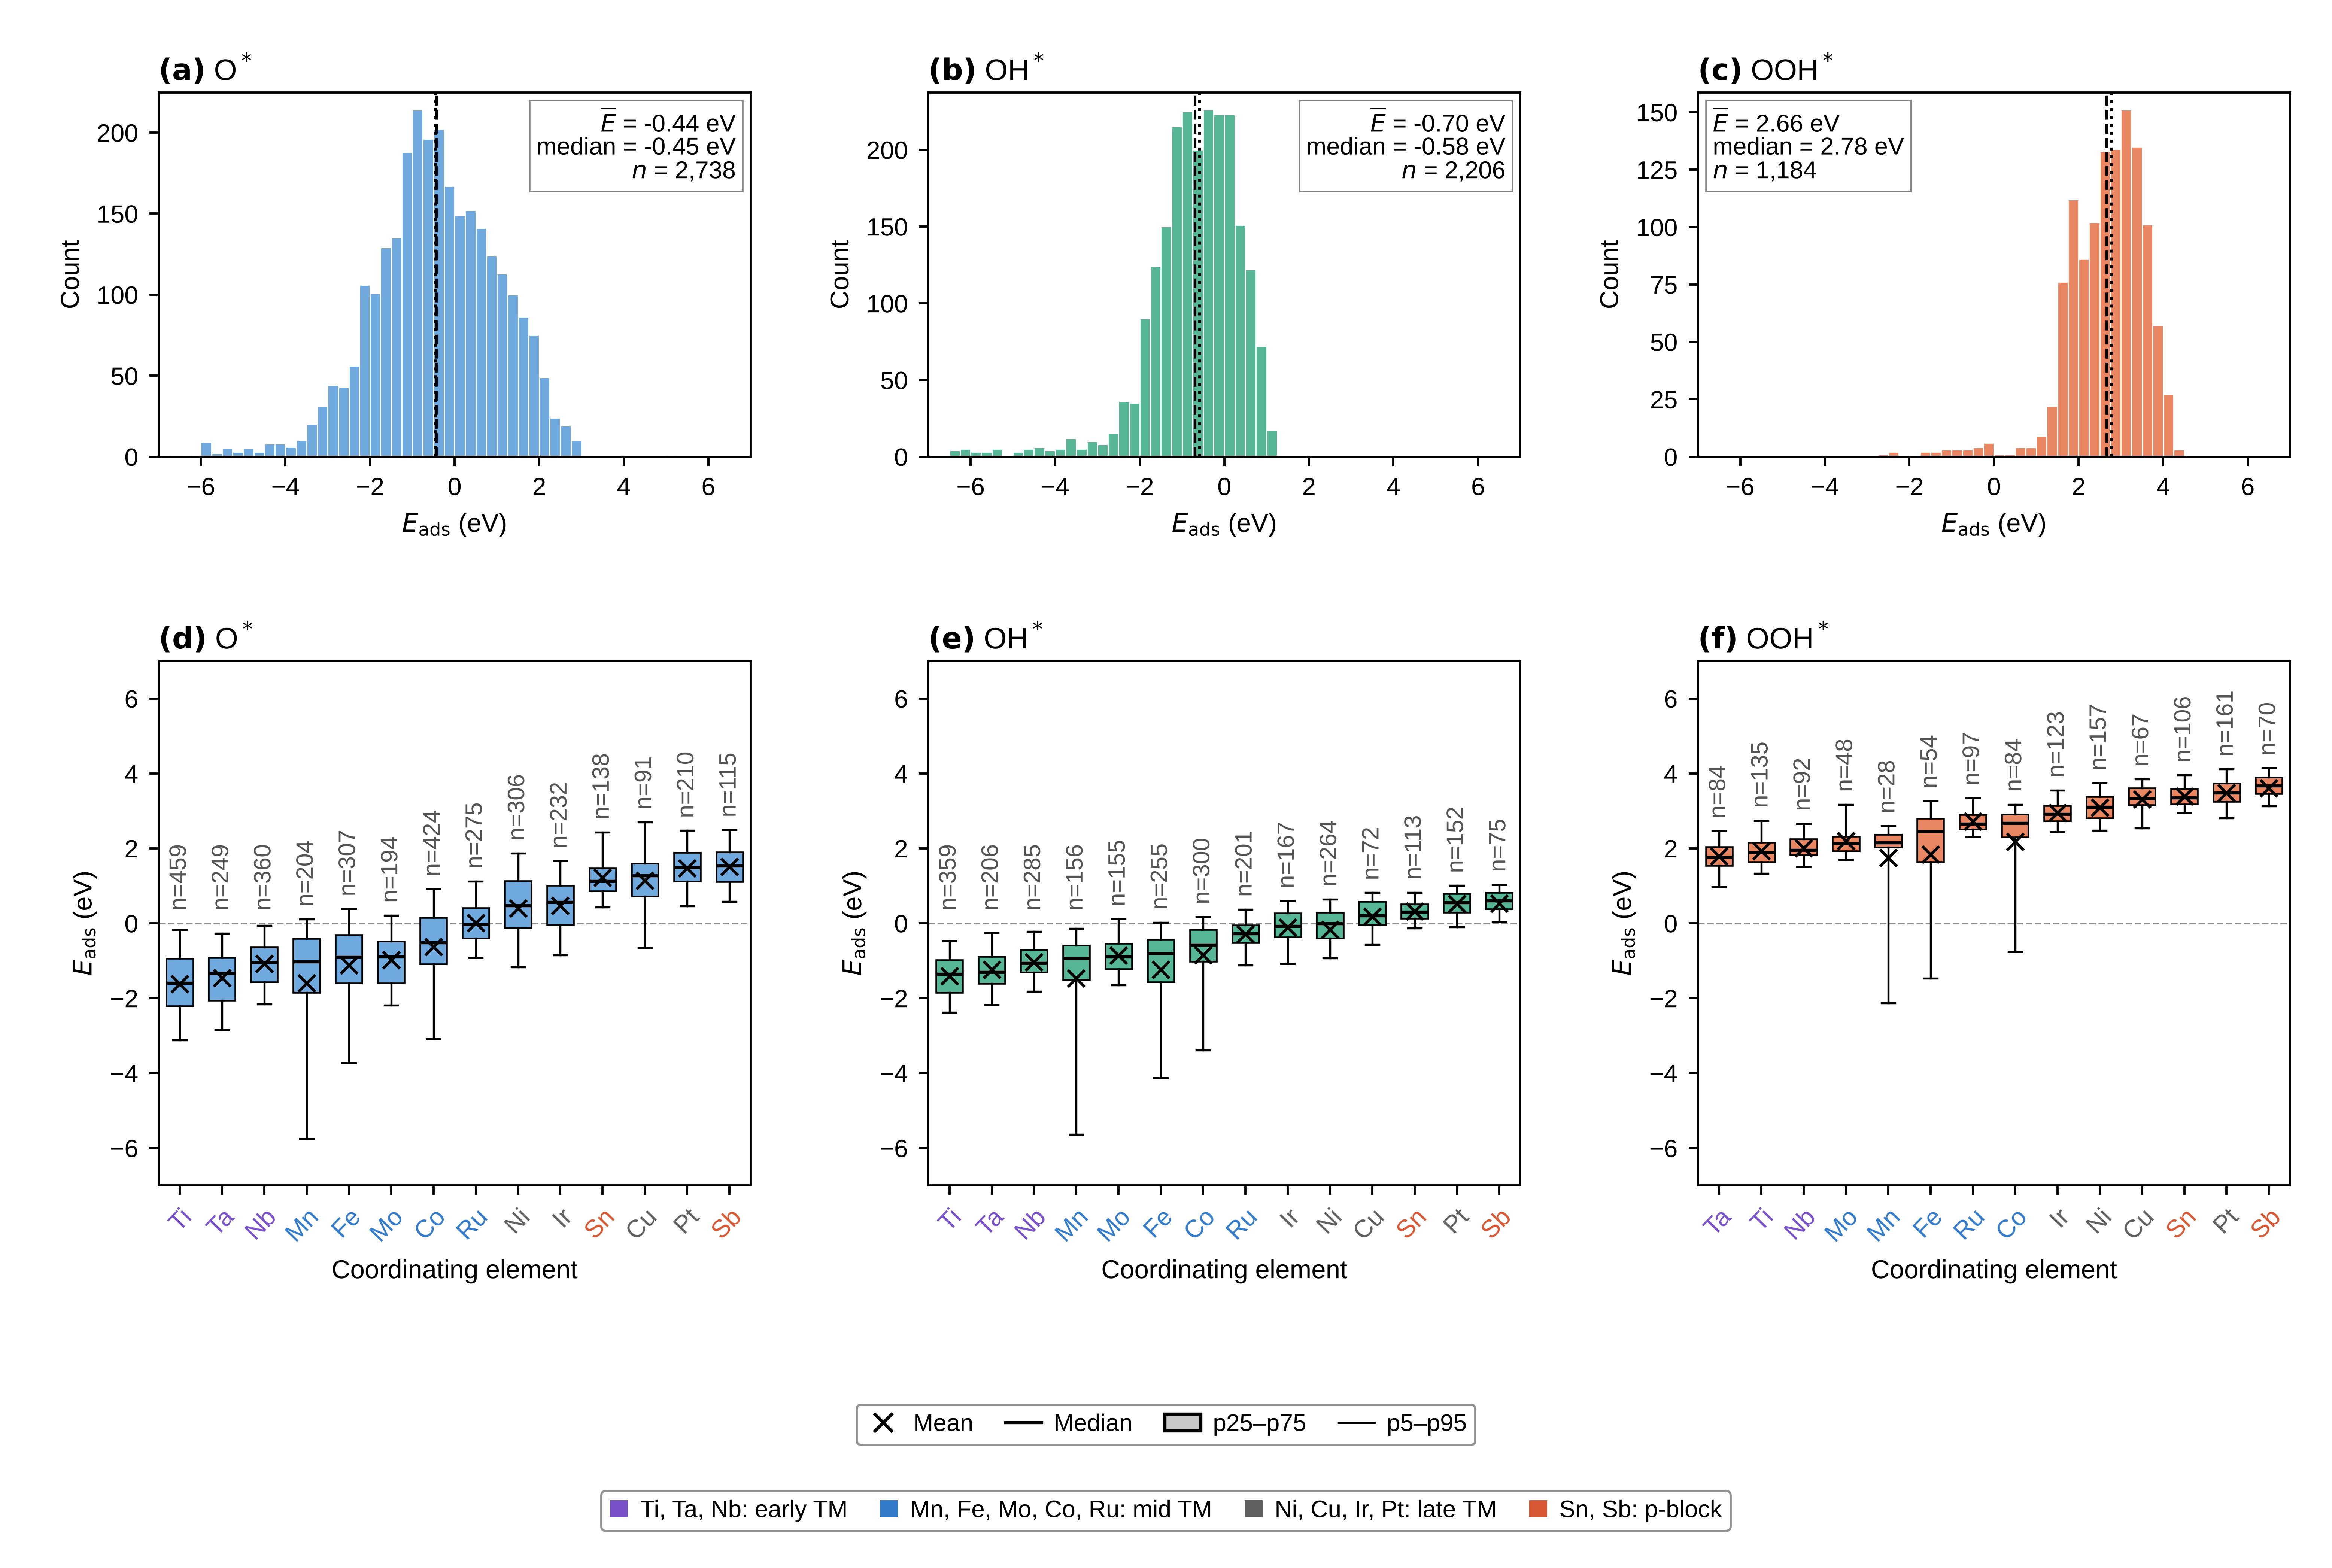

In [3]:
COLORS = {"O": "#70A9DE", "OH": "#56B696", "OOH": "#E98762"}
S1_ELEMENT_GROUPS = (
    ("early TM", ("Ti", "Ta", "Nb"), "#7951C8"),
    ("mid TM", ("Mn", "Fe", "Mo", "Co", "Ru"), "#337CCC"),
    ("late TM", ("Ni", "Cu", "Ir", "Pt"), "#606060"),
    ("p-block", ("Sn", "Sb"), "#D95934"),
)
element_colors = {
    element: color for _, elements, color in S1_ELEMENT_GROUPS for element in elements
}
energy_label = r"$E_{\mathrm{ads}}$ (eV)"

bins = np.linspace(*ENERGY_WINDOW, round((ENERGY_WINDOW[1] - ENERGY_WINDOW[0]) / 0.25) + 1)


def panel_title(ax, letter, intermediate):
    ax.set_title(rf"$\mathbf{{({letter})}}$ {intermediate}$^*$", loc="left", pad=4)


def element_box_stats(energies):
    boxes = []
    for element, group in energies:
        p5, q1, median, q3, p95 = np.percentile(group, [5, 25, 50, 75, 95])
        boxes.append({
            "label": element, "whislo": p5, "q1": q1, "med": median,
            "q3": q3, "whishi": p95, "mean": group.mean(), "n": len(group),
        })
    return sorted(boxes, key=lambda box: box["med"])


with plt.rc_context({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8,
    "axes.titlesize": 9.5,
    "axes.labelsize": 8.3,
    "axes.spines.top": True,
    "axes.spines.right": True,
    "axes.linewidth": 0.7,
    "pdf.fonttype": 42,
}):
    fig, axes = plt.subplots(
        2, 3, figsize=(10.38, 6.98), gridspec_kw={"height_ratios": [1, 1.44]},
    )
    fig.subplots_adjust(
        left=0.068, right=0.982, bottom=0.244, top=0.941, wspace=0.30, hspace=0.46,
    )

    for i, adsorbate in enumerate(ADSORBATES):
        hist_ax, box_ax = axes[:, i]
        color = COLORS[adsorbate]
        energies = minima.loc[minima["adsorbate"].eq(adsorbate), ENERGY]
        if energies.empty:
            raise ValueError(f"No {adsorbate} minima remain inside ENERGY_WINDOW.")
        mean, median = energies.mean(), energies.median()

        hist_ax.hist(energies, bins=bins, color=color, edgecolor="white", linewidth=0.35)
        hist_ax.axvline(mean, color="black", linewidth=0.85, linestyle="--")
        hist_ax.axvline(median, color="black", linewidth=0.95, linestyle=":")
        panel_title(hist_ax, "abc"[i], adsorbate)
        hist_ax.set(xlim=ENERGY_WINDOW, xlabel=energy_label, ylabel="Count")
        hist_ax.xaxis.set_major_locator(MultipleLocator(2))

        place_left = adsorbate == "OOH"
        hist_ax.text(
            0.025 if place_left else 0.975, 0.96,
            "\n".join((
                rf"$\overline{{E}}$ = {mean:.2f} eV",
                f"median = {median:.2f} eV",
                rf"$n$ = {len(energies):,}",
            )),
            transform=hist_ax.transAxes,
            ha="left" if place_left else "right", va="top",
            fontsize=7.8, linespacing=1.13,
            bbox={"boxstyle": "square,pad=0.28", "facecolor": "white",
                  "edgecolor": "#858585", "linewidth": 0.55},
        )

        groups = element_contacts.loc[element_contacts["adsorbate"].eq(adsorbate)].groupby("element")[ENERGY]
        boxes = element_box_stats(groups)
        if not boxes:
            raise ValueError(f"No slab contacts found for {adsorbate}.")
        box_ax.bxp(
            boxes, widths=0.63, patch_artist=True, showmeans=True, showfliers=False,
            boxprops={"facecolor": color, "edgecolor": "black", "linewidth": 0.55},
            medianprops={"color": "black", "linewidth": 1.0},
            meanprops={"marker": "x", "markeredgecolor": "black", "markersize": 5.4,
                       "markeredgewidth": 0.9},
            whiskerprops={"color": "black", "linewidth": 0.65},
            capprops={"color": "black", "linewidth": 0.65},
        )
        box_ax.set_xticks(
            range(1, len(boxes) + 1), [box["label"] for box in boxes],
            rotation=46, ha="right", rotation_mode="anchor",
        )
        for tick in box_ax.get_xticklabels():
            tick.set_color(element_colors.get(tick.get_text(), "#252525"))

        box_ax.set_ylim(*ENERGY_WINDOW)
        for position, box in enumerate(boxes, start=1):
            box_ax.annotate(
                f"n={box['n']:,}", (position, max(0, box["whishi"])), xytext=(0, 4),
                textcoords="offset points", rotation=90, ha="center", va="bottom",
                fontsize=7.6, color="#545454",
            )
        box_ax.axhline(0, color="#898989", linestyle="--", linewidth=0.55, zorder=0)
        panel_title(box_ax, "def"[i], adsorbate)
        box_ax.set(xlabel="Coordinating element", ylabel=energy_label)

        for ax in (hist_ax, box_ax):
            ax.set_axisbelow(True)
            ax.tick_params(width=0.7, length=3.0)

    stat_handles = [
        Line2D([], [], color="black", linestyle="none", marker="x", label="Mean"),
        Line2D([], [], color="black", linewidth=1.0, label="Median"),
        Patch(facecolor="#C8C8C8", edgecolor="black", label="p25–p75"),
        Line2D([], [], color="black", linewidth=0.65, label="p5–p95"),
    ]
    group_handles = [
        Patch(facecolor=color, label=f"{', '.join(elements)}: {group}")
        for group, elements, color in S1_ELEMENT_GROUPS
    ]
    for handles, y, handlelength in ((stat_handles, 0.071, 1.5), (group_handles, 0.016, 0.75)):
        legend = fig.legend(
            handles=handles, loc="lower center", bbox_to_anchor=(0.5, y), ncols=4,
            frameon=True, framealpha=1, facecolor="white", edgecolor="#929292",
            fontsize=7.7, handlelength=handlelength, handletextpad=0.5,
            columnspacing=1.35, borderpad=0.36,
        )
        legend.get_frame().set_linewidth(0.7)

    export_figure(fig, "Figure_S1")

## Figure S2. Adsorption-site preferences of the ORR intermediates (Supporting Information)

Panels **a**, **b**, and **d** use the site-family minima with a top, bridge, or
hollow (threefold or fourfold) geometry. Geometries that match none of these motifs
are flagged for review by the site detector and are not included (11% of the O$^{*}$,
8% of the OH$^{*}$, and 5% of the OOH$^{*}$ site-family minima).
**a.** Share of the site-family minima at each motif. **b.** O$^{*}$ adsorption energy
above the lowest O$^{*}$ energy on the same slab. Boxes span the 25th–75th percentiles,
whiskers the 5th–95th percentiles, and labels give the medians. **c.** Median
O$^{*}$ adsorption energy of the site-family minima contacting each element, against
its Pauling electronegativity; marker area scales with the number of minima, and the
dashed line is an unweighted linear fit. **d.** Motif of the lowest-energy
configuration of each intermediate on the 542 bimetallic surfaces with accepted
minima for all three intermediates.

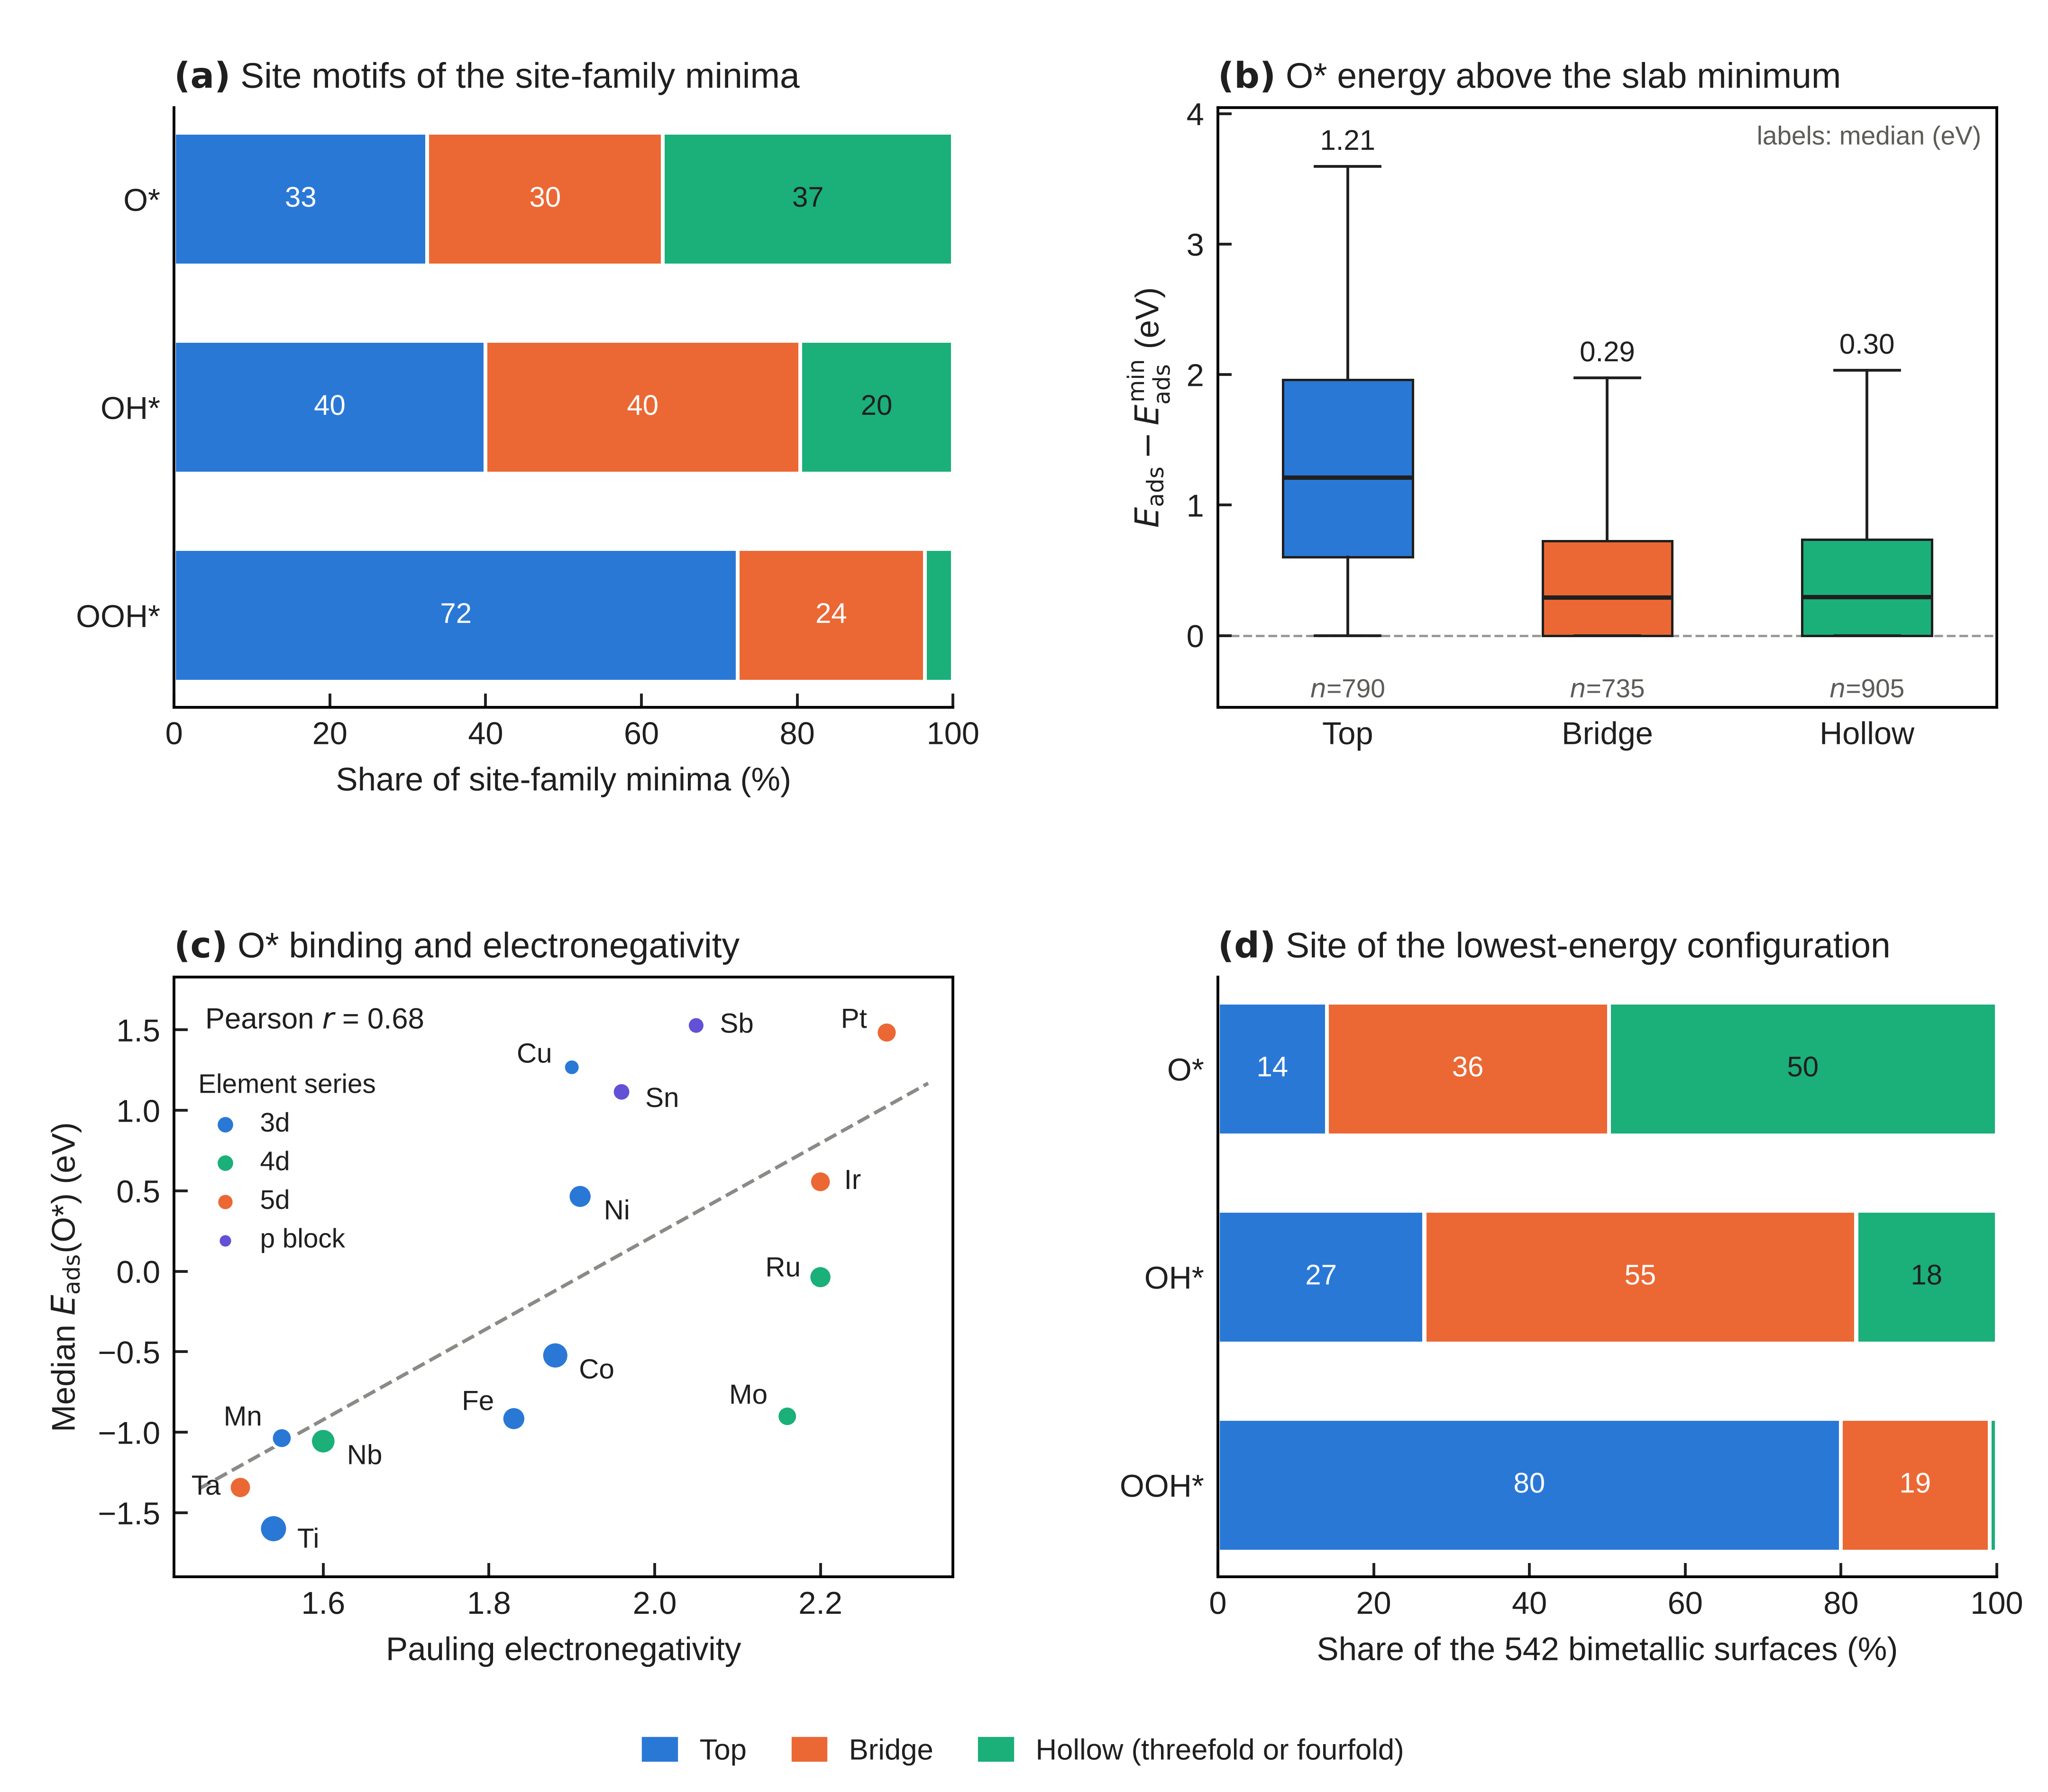

Pearson r = 0.682; O* bridge or hollow with OOH* top: 345 of 542 surfaces


In [4]:
def read_stage_table(name):
    """Read another Stage I table from the CSV folder or the repository ZIP."""
    folder = Path(DATA_DIR).expanduser()
    if (folder / name).is_file():
        return pd.read_csv(folder / name)
    if (folder / TABLES_ZIP).is_file():
        with ZipFile(folder / TABLES_ZIP) as archive, archive.open(name) as handle:
            return pd.read_csv(handle)
    with urlopen(GITHUB_ZIP, timeout=60) as response:
        payload = BytesIO(response.read())
    with ZipFile(payload) as archive, archive.open(name) as handle:
        return pd.read_csv(handle)


from matplotlib.patches import Rectangle

PT = "mp-126_111"
DELTA = SYSTEM_DELTA
MOTIF_ORDER = ["top", "bridge", "hollow"]
MOTIF_LABEL = {"top": "Top", "bridge": "Bridge", "hollow": "Hollow (threefold or fourfold)"}
MOTIF_COLOR = {"top": "#2a78d6", "bridge": "#eb6834", "hollow": "#1baf7a"}
SERIES_COLOR = {"3d": "#2a78d6", "4d": "#1baf7a", "5d": "#eb6834", "p block": "#6250d6"}
SERIES = {"3d": ["Ti", "Mn", "Fe", "Co", "Ni", "Cu"], "4d": ["Nb", "Mo", "Ru"],
          "5d": ["Ta", "Ir", "Pt"], "p block": ["Sn", "Sb"]}
EN = {"Ti": 1.54, "Mn": 1.55, "Fe": 1.83, "Co": 1.88, "Ni": 1.91, "Cu": 1.90, "Nb": 1.60,
      "Mo": 2.16, "Ru": 2.20, "Ta": 1.50, "Ir": 2.20, "Pt": 2.28, "Sn": 1.96, "Sb": 2.05}
INK, MUTED = "#1f1f1f", "#5b5b58"


def motif(site_type):
    """Top, bridge, or hollow; irregular geometries (flagged for review) return None."""
    return {"top": "top", "bridge": "bridge", "3-fold": "hollow", "4-fold": "hollow"}.get(site_type)


families = minima.copy()  # site-family minima inside ENERGY_WINDOW
families["motif"] = families["site_type"].map(motif)
all_oxygen = families[families["adsorbate"] == "O"]
families = families[families["motif"].notna()]

system_minima = read_stage_table("orr_eqv2_global_minimum_configuration_per_system.csv")
system_minima = system_minima[system_minima["surface_id"] != PT]
lowest = system_minima.pivot(index="surface_id", columns="adsorbate", values="site_type").dropna()

with plt.rc_context({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 9, "axes.spines.top": True, "axes.spines.right": True, "axes.labelsize": 8.3, "axes.linewidth": 0.7,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.major.width": 0.7,
    "ytick.major.width": 0.7, "pdf.fonttype": 42, "svg.fonttype": "none",
    "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
}):

    fig = plt.figure(figsize=(7.2, 6.3))
    grid = fig.add_gridspec(2, 2, left=0.085, right=0.975, top=0.94, bottom=0.12,
                            wspace=0.34, hspace=0.45)
    ax_a, ax_b = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])
    ax_c, ax_d = fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])
    source = {}


    def title(ax, letter, text):
        ax.set_title(rf"$\mathbf{{({letter})}}$ {text}", loc="left", pad=5)


    # (a) Share of site families by motif
    shares = (pd.crosstab(families["adsorbate"], families["motif"], normalize="index") * 100
              ).reindex(index=ADSORBATES, columns=MOTIF_ORDER, fill_value=0)
    counts = families["adsorbate"].value_counts().reindex(ADSORBATES)
    source["a_motif_share_pct"] = shares
    for row, ads in enumerate(ADSORBATES):
        left = 0.0
        for m in MOTIF_ORDER:
            width = shares.loc[ads, m]
            ax_a.barh(row, width - 0.5, left=left + 0.25, height=0.62, color=MOTIF_COLOR[m],
                      edgecolor="none")
            if width >= 6:
                ax_a.text(left + width / 2, row, f"{width:.0f}", ha="center", va="center",
                          fontsize=7.2, color="white" if m in ("top", "bridge") else INK)
            left += width
    ax_a.set_yticks(range(3), [f"{a}*" for a in ADSORBATES])
    ax_a.invert_yaxis()
    ax_a.set_xlim(0, 100)
    ax_a.set_xlabel("Share of site-family minima (%)")
    ax_a.tick_params(axis="y", length=0)
    for side in ("top", "right"):
        ax_a.spines[side].set_visible(False)
    title(ax_a, "a", "Site motifs of the site-family minima")

    # (b) O* energy above the slab minimum, by motif
    oxygen = families[families["adsorbate"] == "O"]
    groups = [oxygen.loc[oxygen["motif"] == m, DELTA].to_numpy() for m in MOTIF_ORDER]
    stats = []
    for m, values in zip(MOTIF_ORDER, groups):
        p5, q1, med, q3, p95 = np.percentile(values, [5, 25, 50, 75, 95])
        stats.append({"label": m, "whislo": p5, "q1": q1, "med": med, "q3": q3, "whishi": p95,
                      "n": len(values)})
    source["b_O_energy_above_minimum"] = pd.DataFrame(stats)
    parts = ax_b.bxp(stats, widths=0.5, patch_artist=True, showfliers=False,
                     medianprops={"color": INK, "linewidth": 1.1},
                     whiskerprops={"color": INK, "linewidth": 0.7},
                     capprops={"color": INK, "linewidth": 0.7},
                     boxprops={"edgecolor": INK, "linewidth": 0.6})
    for box, m in zip(parts["boxes"], MOTIF_ORDER):
        box.set_facecolor(MOTIF_COLOR[m])
    for pos, st in enumerate(stats, start=1):
        ax_b.text(pos, st["whishi"] + 0.08, f"{st['med']:.2f}", ha="center", va="bottom",
                  fontsize=7.2, color=INK)
        ax_b.text(pos, -0.33, f"$n$={st['n']:,}", ha="center", va="top", fontsize=6.6, color=MUTED)
    ax_b.set_xticks(range(1, 4), ["Top", "Bridge", "Hollow"])
    ax_b.set_ylim(-0.55, max(st["whishi"] for st in stats) + 0.45)
    ax_b.set_ylabel(r"$E_{\mathrm{ads}} - E_{\mathrm{ads}}^{\mathrm{min}}$ (eV)")
    ax_b.axhline(0, color="#9a9a96", linewidth=0.6, linestyle="--", zorder=0)
    ax_b.tick_params(axis="x", length=0)
    title(ax_b, "b", "O* energy above the slab minimum")
    ax_b.text(0.98, 0.97, "labels: median (eV)", transform=ax_b.transAxes, ha="right", va="top",
              fontsize=6.6, color=MUTED)

    # (c) Median O* adsorption energy versus Pauling electronegativity
    def contact_elements(encoded):
        return sorted({c["symbol"] for shell in json.loads(encoded).values() for c in shell})


    per_element = (all_oxygen.assign(element=all_oxygen["oxygen_contacts_json"].map(contact_elements))
                   .explode("element").groupby("element")[ENERGY].agg(["median", "size"]))
    per_element["EN"] = per_element.index.map(EN)
    per_element["series"] = per_element.index.map(
        {e: s for s, members in SERIES.items() for e in members})
    source["c_O_median_vs_electronegativity"] = per_element
    x, y = per_element["EN"].to_numpy(), per_element["median"].to_numpy()
    r = np.corrcoef(x, y)[0, 1]
    slope, intercept = np.polyfit(x, y, 1)
    fx = np.linspace(1.45, 2.33, 50)
    ax_c.plot(fx, slope * fx + intercept, color="#8a8a86", linewidth=0.9, linestyle="--", zorder=1)
    for s, color in SERIES_COLOR.items():
        sub = per_element[per_element["series"] == s]
        ax_c.scatter(sub["EN"], sub["median"], s=10 + 0.09 * sub["size"], color=color,
                     edgecolor="white", linewidth=0.8, zorder=3, label=s)
    offsets = {"Ta": (-5, 0), "Ti": (6, -3), "Mn": (-5, 5), "Nb": (6, -4), "Fe": (-5, 4),
               "Co": (6, -4), "Cu": (-5, 3), "Ni": (6, -4), "Sn": (6, -2), "Mo": (-5, 5),
               "Ru": (-5, 2), "Ir": (6, 0), "Pt": (-5, 3), "Sb": (6, 0)}
    for element, row in per_element.iterrows():
        dx, dy = offsets[element]
        ax_c.annotate(element, (row["EN"], row["median"]), xytext=(dx, dy),
                      textcoords="offset points", ha="left" if dx > 0 else "right",
                      va="center", fontsize=7, color=INK)
    ax_c.text(0.04, 0.95, rf"Pearson $r$ = {r:.2f}", transform=ax_c.transAxes, va="top", fontsize=7.4)
    ax_c.set_xlim(1.42, 2.36)
    ax_c.set_ylim(y.min() - 0.3, y.max() + 0.3)
    ax_c.set_xlabel("Pauling electronegativity")
    ax_c.set_ylabel(r"Median $E_{\mathrm{ads}}$(O*) (eV)")
    ax_c.legend(loc="upper left", bbox_to_anchor=(0.0, 0.88), fontsize=6.8, frameon=False,
                handletextpad=0.3, markerscale=0.8, title="Element series", title_fontsize=6.8,
                alignment="left")
    title(ax_c, "c", "O* binding and electronegativity")

    # (d) Site of the lowest-energy configuration on each surface
    site_of_minimum = lowest.apply(lambda column: column.map(motif))
    complete = len(site_of_minimum)
    min_shares = pd.DataFrame({
        ads: site_of_minimum[ads].value_counts() / site_of_minimum[ads].notna().sum() * 100
        for ads in ADSORBATES
    }).T.reindex(index=ADSORBATES, columns=MOTIF_ORDER, fill_value=0)
    source["d_lowest_energy_site_share_pct"] = min_shares
    for row, ads in enumerate(ADSORBATES):
        left = 0.0
        for m in MOTIF_ORDER:
            width = min_shares.loc[ads, m]
            ax_d.barh(row, max(width - 0.5, 0), left=left + 0.25, height=0.62,
                      color=MOTIF_COLOR[m], edgecolor="none")
            if width >= 6:
                ax_d.text(left + width / 2, row, f"{width:.0f}", ha="center", va="center",
                          fontsize=7.2, color="white" if m in ("top", "bridge") else INK)
            left += width
    ax_d.set_yticks(range(3), [f"{a}*" for a in ADSORBATES])
    ax_d.invert_yaxis()
    ax_d.set_xlim(0, 100)
    ax_d.set_xlabel(f"Share of the {complete} bimetallic surfaces (%)")
    ax_d.tick_params(axis="y", length=0)
    for side in ("top", "right"):
        ax_d.spines[side].set_visible(False)
    title(ax_d, "d", "Site of the lowest-energy configuration")
    n_pattern = int(((site_of_minimum["O"].isin(["bridge", "hollow"]))
                     & (site_of_minimum["OOH"] == "top")).sum())

    fig.legend(handles=[Patch(color=MOTIF_COLOR[m], label=MOTIF_LABEL[m]) for m in MOTIF_ORDER],
               loc="lower center", bbox_to_anchor=(0.5, 0.0), ncols=3, frameon=False, fontsize=7.4,
               handlelength=1.1, columnspacing=1.6)
    for name, frame in source.items():
        frame.to_csv(OUTPUT_DIR / f"Figure_S2_{name}.csv")
    export_figure(fig, "Figure_S2")
    print(f"Pearson r = {r:.3f}; O* bridge or hollow with OOH* top: {n_pattern} of {complete} surfaces")


## Contacting elements and adsorption energies (descriptive statistics)

**a.** Percentage of site-family minima for which a given slab element is in
direct first-shell contact with the adsorbate. Each distinct element is counted
once per site-family minimum, including contacts to either oxygen of OOH*.
A family with several contacting elements contributes to each of those elements,
so percentages can sum to more than 100% within an intermediate.
**b.** Median EqV2-predicted adsorption energy among the minima containing that
contact. **c.** Median energy difference above the lowest validated EqV2
adsorption energy in the same slab–adsorbate system. Elements are grouped by
transition-metal series (3d, 4d, 5d) and p block. Percentages use the number of retained
site-family minima for the corresponding intermediate. Energies in panel **c**
retain the lowest validated system energy from the screening run as their reference.

In [5]:
element_summary = element_contacts.groupby(["element", "adsorbate"], as_index=False).agg(
    n_families=("system_id", "size"),
    median_adsorption_energy_eV=(ENERGY, "median"),
    median_above_minimum_eV=(SYSTEM_DELTA, "median"),
)
element_summary["occurrence_pct"] = (
    100 * element_summary["n_families"] / element_summary["adsorbate"].map(totals)
)
element_summary.to_csv(OUTPUT_DIR / "contact_elements_source_data.csv", index=False)

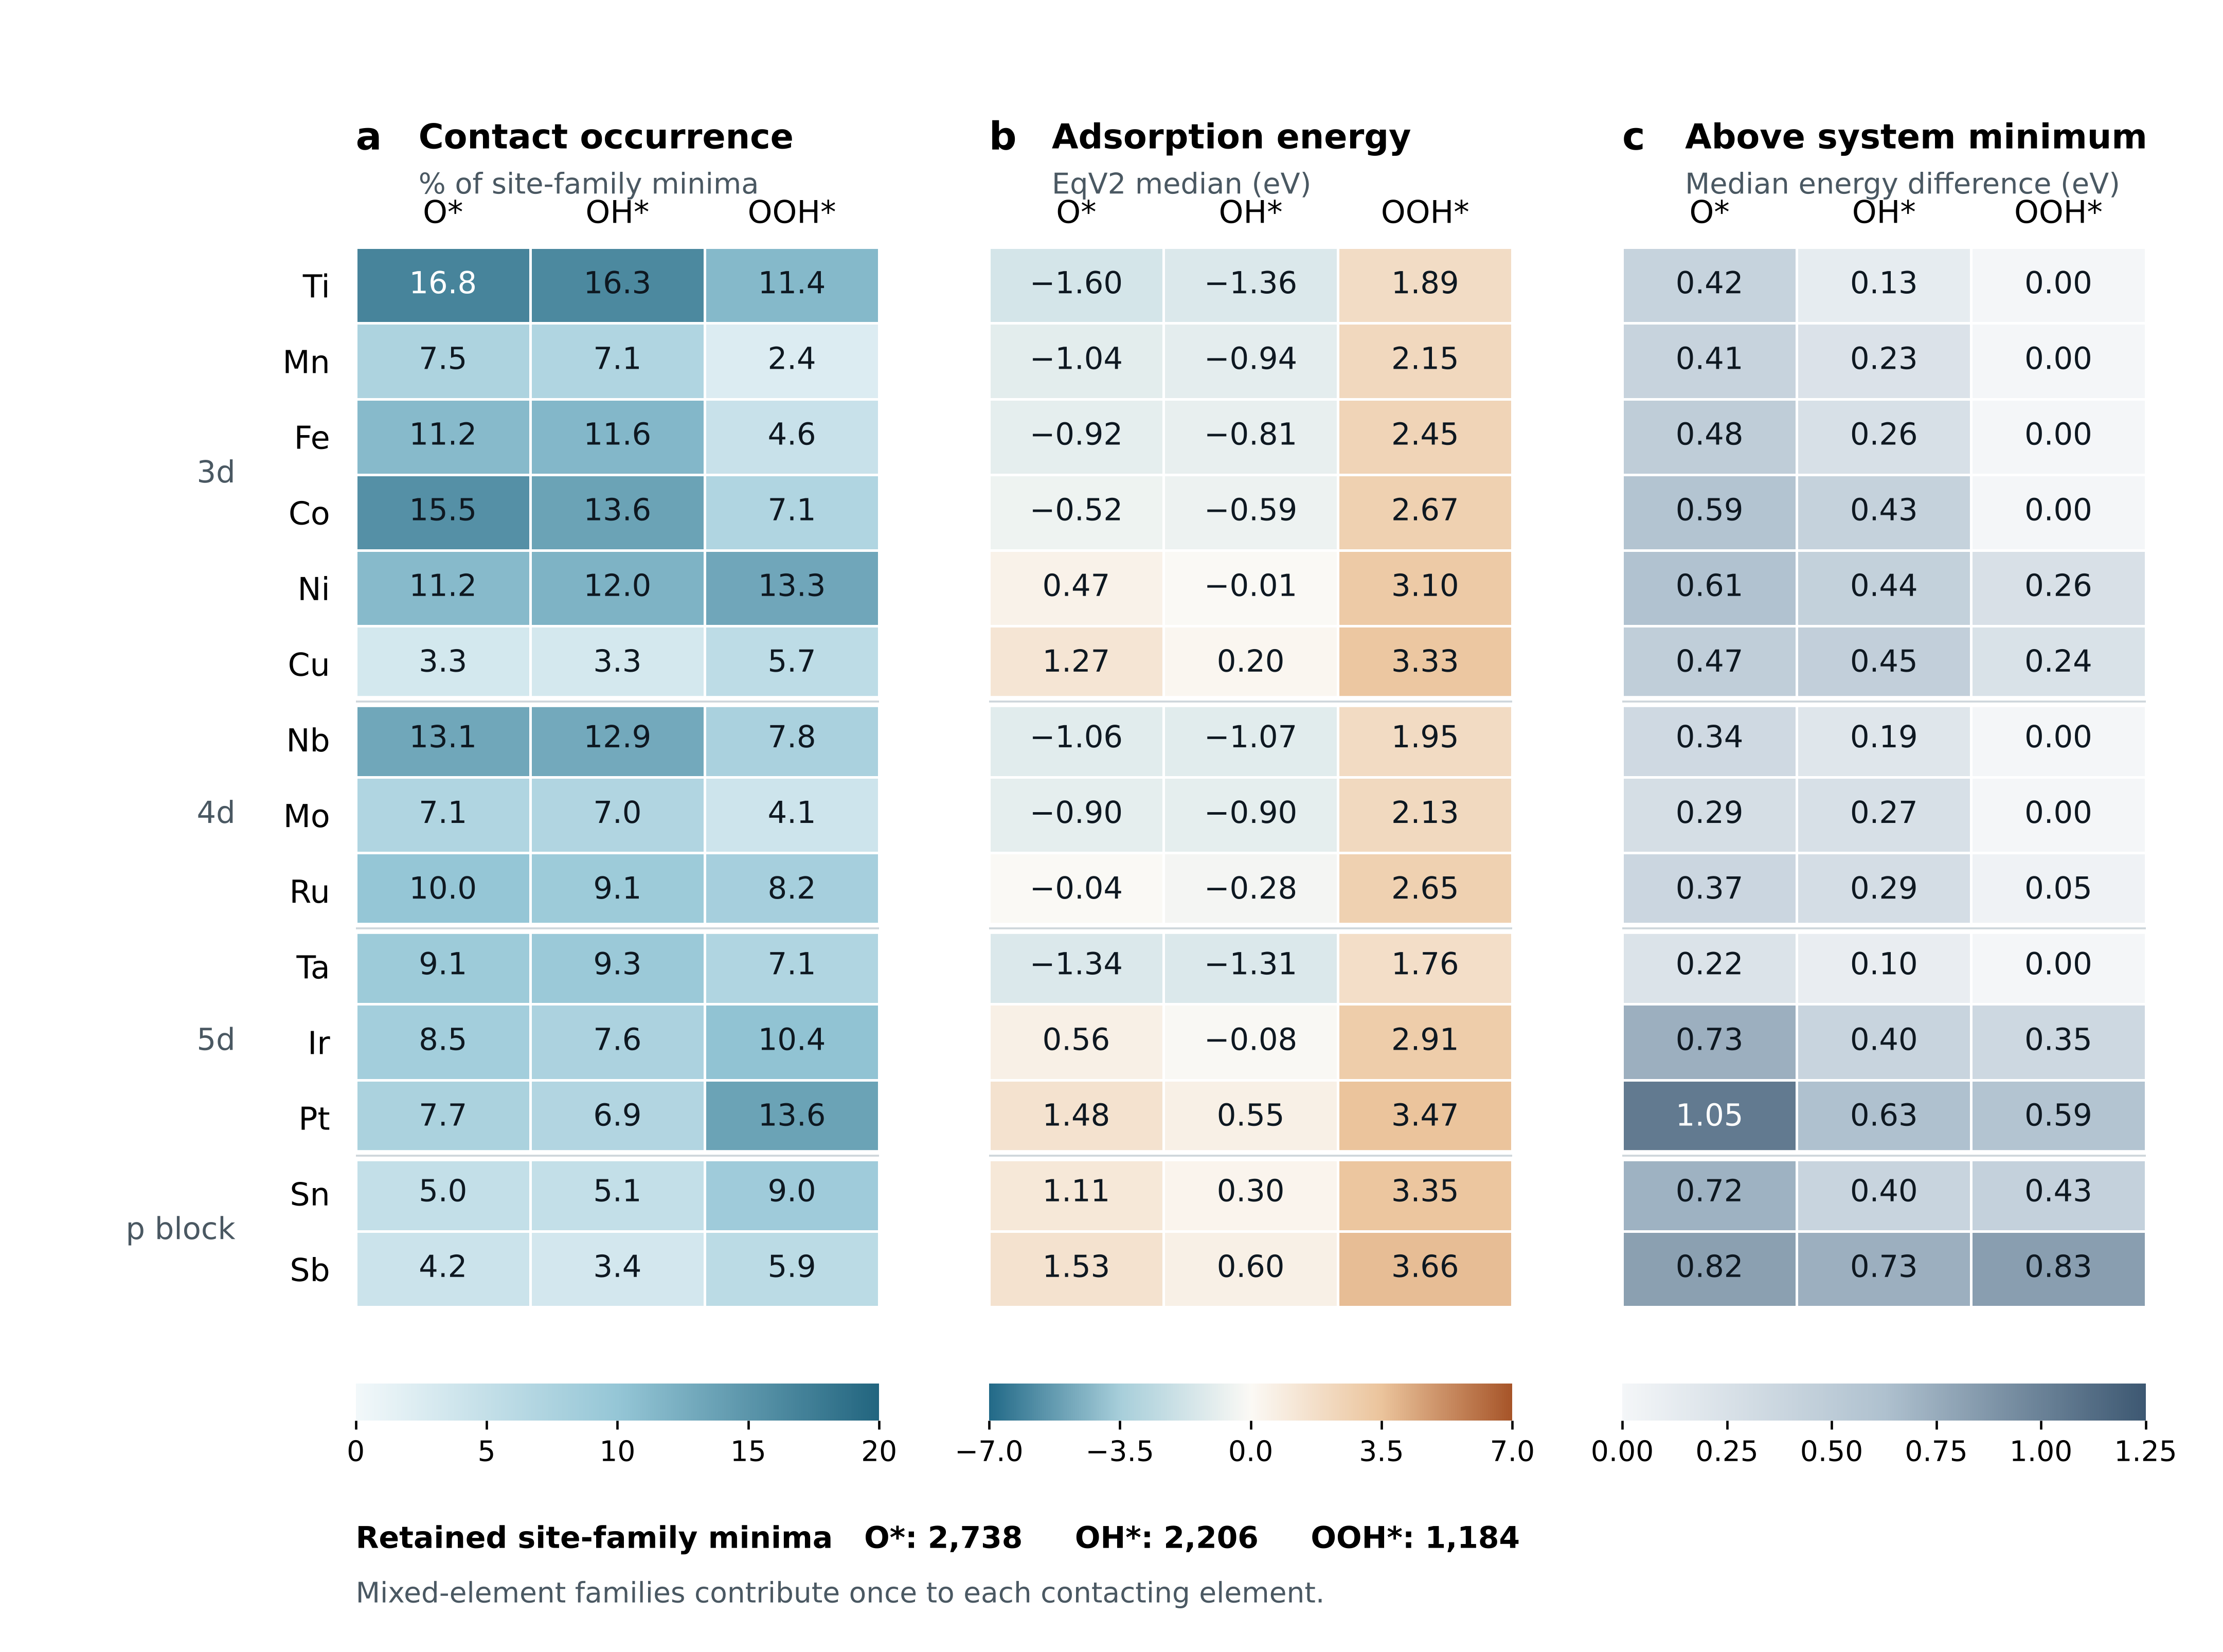

In [6]:
def ink_for(background):
    channels = np.array(background[:3])
    linear = np.where(channels <= 0.04045, channels / 12.92, ((channels + 0.055) / 1.055) ** 2.4)
    luminance = float(linear @ np.array([0.2126, 0.7152, 0.0722]))
    return "white" if luminance < 0.21 else "#0E1821"


def draw_panel(ax, values, norm, cmap, label, heading, unit, digits):
    tile_map = ax.pcolormesh(
        np.arange(4), np.arange(len(ELEMENTS) + 1), np.ma.masked_invalid(values),
        cmap=cmap, norm=norm, edgecolors="white", linewidth=0.6, antialiased=True,
    )
    ax.set_xlim(0, 3)
    ax.set_ylim(len(ELEMENTS), 0)
    ax.set_xticks(np.arange(3) + 0.5, [f"{name}*" for name in ADSORBATES])
    ax.xaxis.tick_top()
    ax.tick_params(axis="x", length=0, pad=4, labelsize=7.3)
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.text(0, 1.102, label, transform=ax.transAxes, fontsize=9, fontweight="bold", va="center")
    ax.text(0.12, 1.102, heading, transform=ax.transAxes, fontsize=8, fontweight="bold", va="center")
    ax.text(0.12, 1.058, unit, transform=ax.transAxes, fontsize=6.7, color="#4A5862", va="center")

    for row, column in np.ndindex(values.shape):
        value = values[row, column]
        if np.isfinite(value):
            text = f"{value:.{digits}f}".replace("-", "−")
            color = ink_for(cmap(norm(value)))
        else:
            text, color = "—", "#616b75"
        ax.text(column + 0.5, row + 0.5, text, color=color, fontsize=7.1, ha="center", va="center")
    return tile_map


def plot_contact_element_heatmap(summary, totals):
    fig = plt.figure(figsize=(183 / 25.4, 136 / 25.4), facecolor="white")
    grid = fig.add_gridspec(
        2, 3, left=0.16, right=0.965, bottom=0.14, top=0.85,
        height_ratios=[1, 0.035], hspace=0.14, wspace=0.21,
    )
    panels = [fig.add_subplot(grid[0, i]) for i in range(3)]

    for ax in panels:
        for row in [6, 9, 12]:
            ax.axhline(row, color="white", linewidth=2.6, zorder=3)
            ax.axhline(row, color="#CED6DB", linewidth=0.45, zorder=4)
    first = panels[0]
    first.set_yticks(np.arange(len(ELEMENTS)) + 0.5, ELEMENTS)
    first.tick_params(axis="y", length=0, pad=6, labelsize=7.4)
    offset = 0
    for name, members in ELEMENT_GROUPS.items():
        first.text(
            -0.23, offset + len(members) / 2, name, transform=first.get_yaxis_transform(),
            ha="right", va="center", color="#4A5862", fontsize=7.1,
        )
        offset += len(members)

    specs = [
        (
            "occurrence_pct", Normalize(0, 20),
            ["#F2F8FA", "#95C6D6", "#22657F"], "a", "Contact occurrence", "% of site-family minima",
            1, [0, 5, 10, 15, 20],
        ),
        (
            "median_adsorption_energy_eV", TwoSlopeNorm(vmin=ENERGY_WINDOW[0], vcenter=0, vmax=ENERGY_WINDOW[1]),
            ["#236A88", "#A7CEDA", "#FBF9F5", "#EBC49C", "#A75529"],
            "b", "Adsorption energy", "EqV2 median (eV)", 2, np.linspace(*ENERGY_WINDOW, 5),
        ),
        (
            "median_above_minimum_eV", Normalize(0, 1.25),
            ["#F4F6F8", "#AFC1CF", "#3D5872"],
            "c", "Above system minimum", "Median energy difference (eV)", 2, [0, 0.25, 0.50, 0.75, 1.00, 1.25],
        ),
    ]
    for i, (key, norm, colors, label, heading, unit, digits, ticks) in enumerate(specs):
        ax = panels[i]
        values = summary.pivot(index="element", columns="adsorbate", values=key).reindex(
            index=ELEMENTS, columns=ADSORBATES,
        ).to_numpy()
        if np.nanmin(values) < norm.vmin or np.nanmax(values) > norm.vmax:
            raise ValueError(f"Color scale does not cover the full data range for {key}.")
        cmap = LinearSegmentedColormap.from_list(key, colors)
        cmap.set_bad("#E2E6EA")
        mappable = draw_panel(ax, values, norm, cmap, label, heading, unit, digits)
        if i == 0:
            ax.set_yticks(np.arange(len(ELEMENTS)) + 0.5, ELEMENTS)
            ax.tick_params(axis="y", length=0, pad=6, labelsize=7.4)
        legend = fig.colorbar(mappable, cax=fig.add_subplot(grid[1, i]), orientation="horizontal", ticks=ticks)
        legend.outline.set_visible(False)
        legend.ax.tick_params(length=2, width=0.55, pad=2.4, labelsize=6.6)

    fig.text(
        0.16, 0.063, "Retained site-family minima   " + "     ".join(f"{name}*: {totals[name]:,}" for name in ADSORBATES),
        fontsize=7, fontweight="bold",
    )
    fig.text(
        0.16, 0.030, "Mixed-element families contribute once to each contacting element.",
        fontsize=6.6, color="#4A5862",
    )
    return fig


export_figure(plot_contact_element_heatmap(element_summary, totals), "contact_elements")

## Radar profiles of adsorption-site motifs (descriptive statistics)

The four axes represent top, bridge, threefold, and fourfold sites. Each
axis gives the percentage of retained site-family minima for that intermediate.
Dashed profiles use the original canonical assignments. Solid profiles
also include inferred motifs for the 542 off-center or irregular geometries.

For each reassignment, the projected first-shell contacts to the anchor oxygen
were tested in subsets of four, three, then two. A hollow motif required the
projected oxygen to lie inside the convex polygon formed by the contact atoms.
A bridge motif required the oxygen projection to fall within 0.65 Å of the
line joining the contacts, with its closest point in the central 80% of the
segment. Among equally sized valid subsets, the one with the smallest sum of
normalized contact distances was selected. If no subset qualified, the contact
with the shortest distance normalized by the sum of covalent radii defined a
top-like motif. The reassignment table records the original motif and
coordination count alongside the inferred motif.

In [7]:
MOTIFS = {"top": "Top", "bridge": "Bridge", "3-fold": "Threefold", "4-fold": "Fourfold"}
MOTIF_BY_CN = {number: label for number, label in enumerate(MOTIFS, start=1)}

def valid_geometry(contacts):
    """Apply the canonical detector's projection tests to an anchor-contact subset."""
    xy = np.asarray([contact["xy"] for contact in contacts])
    if len(contacts) == 2:
        vector = xy[1] - xy[0]
        squared_length = vector @ vector
        if squared_length < 1e-10:
            return False
        projection = -xy[0] @ vector / squared_length
        residual = np.linalg.norm(xy[0] + projection * vector)
        return 0.10 <= projection <= 0.90 and residual <= 0.65
    try:
        hull = ConvexHull(xy)
    except QhullError:
        return False
    return len(hull.vertices) == len(contacts) and (hull.equations[:, -1] <= 1e-7).all()


def anchor_contacts(record):
    contacts_by_oxygen = json.loads(record["oxygen_contacts_json"])
    contacts = contacts_by_oxygen[str(int(record["binding_oxygen_index"]))]
    if not contacts or len(contacts) != record["coordination"]:
        raise ValueError(f"Missing or inconsistent anchor contacts for {record['unique_site_key']}.")
    return sorted(contacts, key=lambda item: (item["ratio"], item["index"], item["image"]))


def infer_motif(contacts):
    """Use the largest canonical subset, then its strongest normalized contacts."""
    for size in range(min(len(contacts), 4), 1, -1):
        candidates = (
            subset for subset in combinations(contacts, size) if valid_geometry(subset)
        )
        best = min(candidates, key=lambda subset: sum(item["ratio"] for item in subset), default=None)
        if best is not None:
            return MOTIF_BY_CN[size], best
    return "top", contacts[:1]



canonical_mask = minima["site_type"].isin(MOTIFS)
assigned_motif = minima["site_type"].copy()
assignment_rows = []
for index, row in minima.loc[~canonical_mask].iterrows():
    motif, subset = infer_motif(anchor_contacts(row))
    assigned_motif.at[index] = motif
    assignment_rows.append({
        "system_id": row["system_id"],
        "adsorbate": row["adsorbate"],
        "site_family": row["site_family"],
        "trajectory_relative_path": row["trajectory_relative_path"],
        "original_motif": row["site_type"],
        "original_anchor_coordination": int(row["coordination"]),
        "assigned_motif": motif,
        "contacts_used": len(subset),
        "selected_slab_atom_indices": json.dumps([item["index"] for item in subset]),
        "selected_slab_atom_images": json.dumps([item["image"] for item in subset]),
        "assignment_method": "canonical_contact_subset" if len(subset) > 1 else "nearest_normalized_contact",
    })

assignment_columns = [
    "system_id", "adsorbate", "site_family", "trajectory_relative_path", "original_motif",
    "original_anchor_coordination", "assigned_motif", "contacts_used",
    "selected_slab_atom_indices", "selected_slab_atom_images", "assignment_method",
]
reassignments = pd.DataFrame(assignment_rows, columns=assignment_columns)
reassignments.to_csv(OUTPUT_DIR / "site_motif_reassignments.csv", index=False)

original_counts = pd.crosstab(minima.loc[canonical_mask, "adsorbate"], minima.loc[canonical_mask, "site_type"])
original_counts = original_counts.reindex(index=ADSORBATES, columns=MOTIFS, fill_value=0)
classified_counts = pd.crosstab(minima["adsorbate"], assigned_motif)
classified_counts = classified_counts.reindex(index=ADSORBATES, columns=MOTIFS, fill_value=0)
if not assigned_motif.isin(MOTIFS).all() or not classified_counts.sum(axis=1).eq(totals).all():
    raise ValueError("Every site-family minimum must contribute one motif.")

motif_data = pd.concat({
    "Original canonical motifs": original_counts,
    "Including inferred motifs": classified_counts,
}, names=["profile", "adsorbate"]).rename_axis(columns="motif").stack().rename("count").reset_index()
motif_data["total_family_minima"] = motif_data["adsorbate"].map(totals)
motif_data["percentage"] = 100 * motif_data["count"] / motif_data["total_family_minima"]
motif_data.to_csv(OUTPUT_DIR / "site_motif_radar_source_data.csv", index=False)

reassigned_counts = (classified_counts - original_counts).rename(columns=MOTIFS)
display(reassigned_counts.assign(Total=reassigned_counts.sum(axis=1)))

site_type,Top,Bridge,Threefold,Fourfold,Total
adsorbate,,,,,
O,181,66,29,32,308
OH,157,21,1,0,179
OOH,55,0,0,0,55


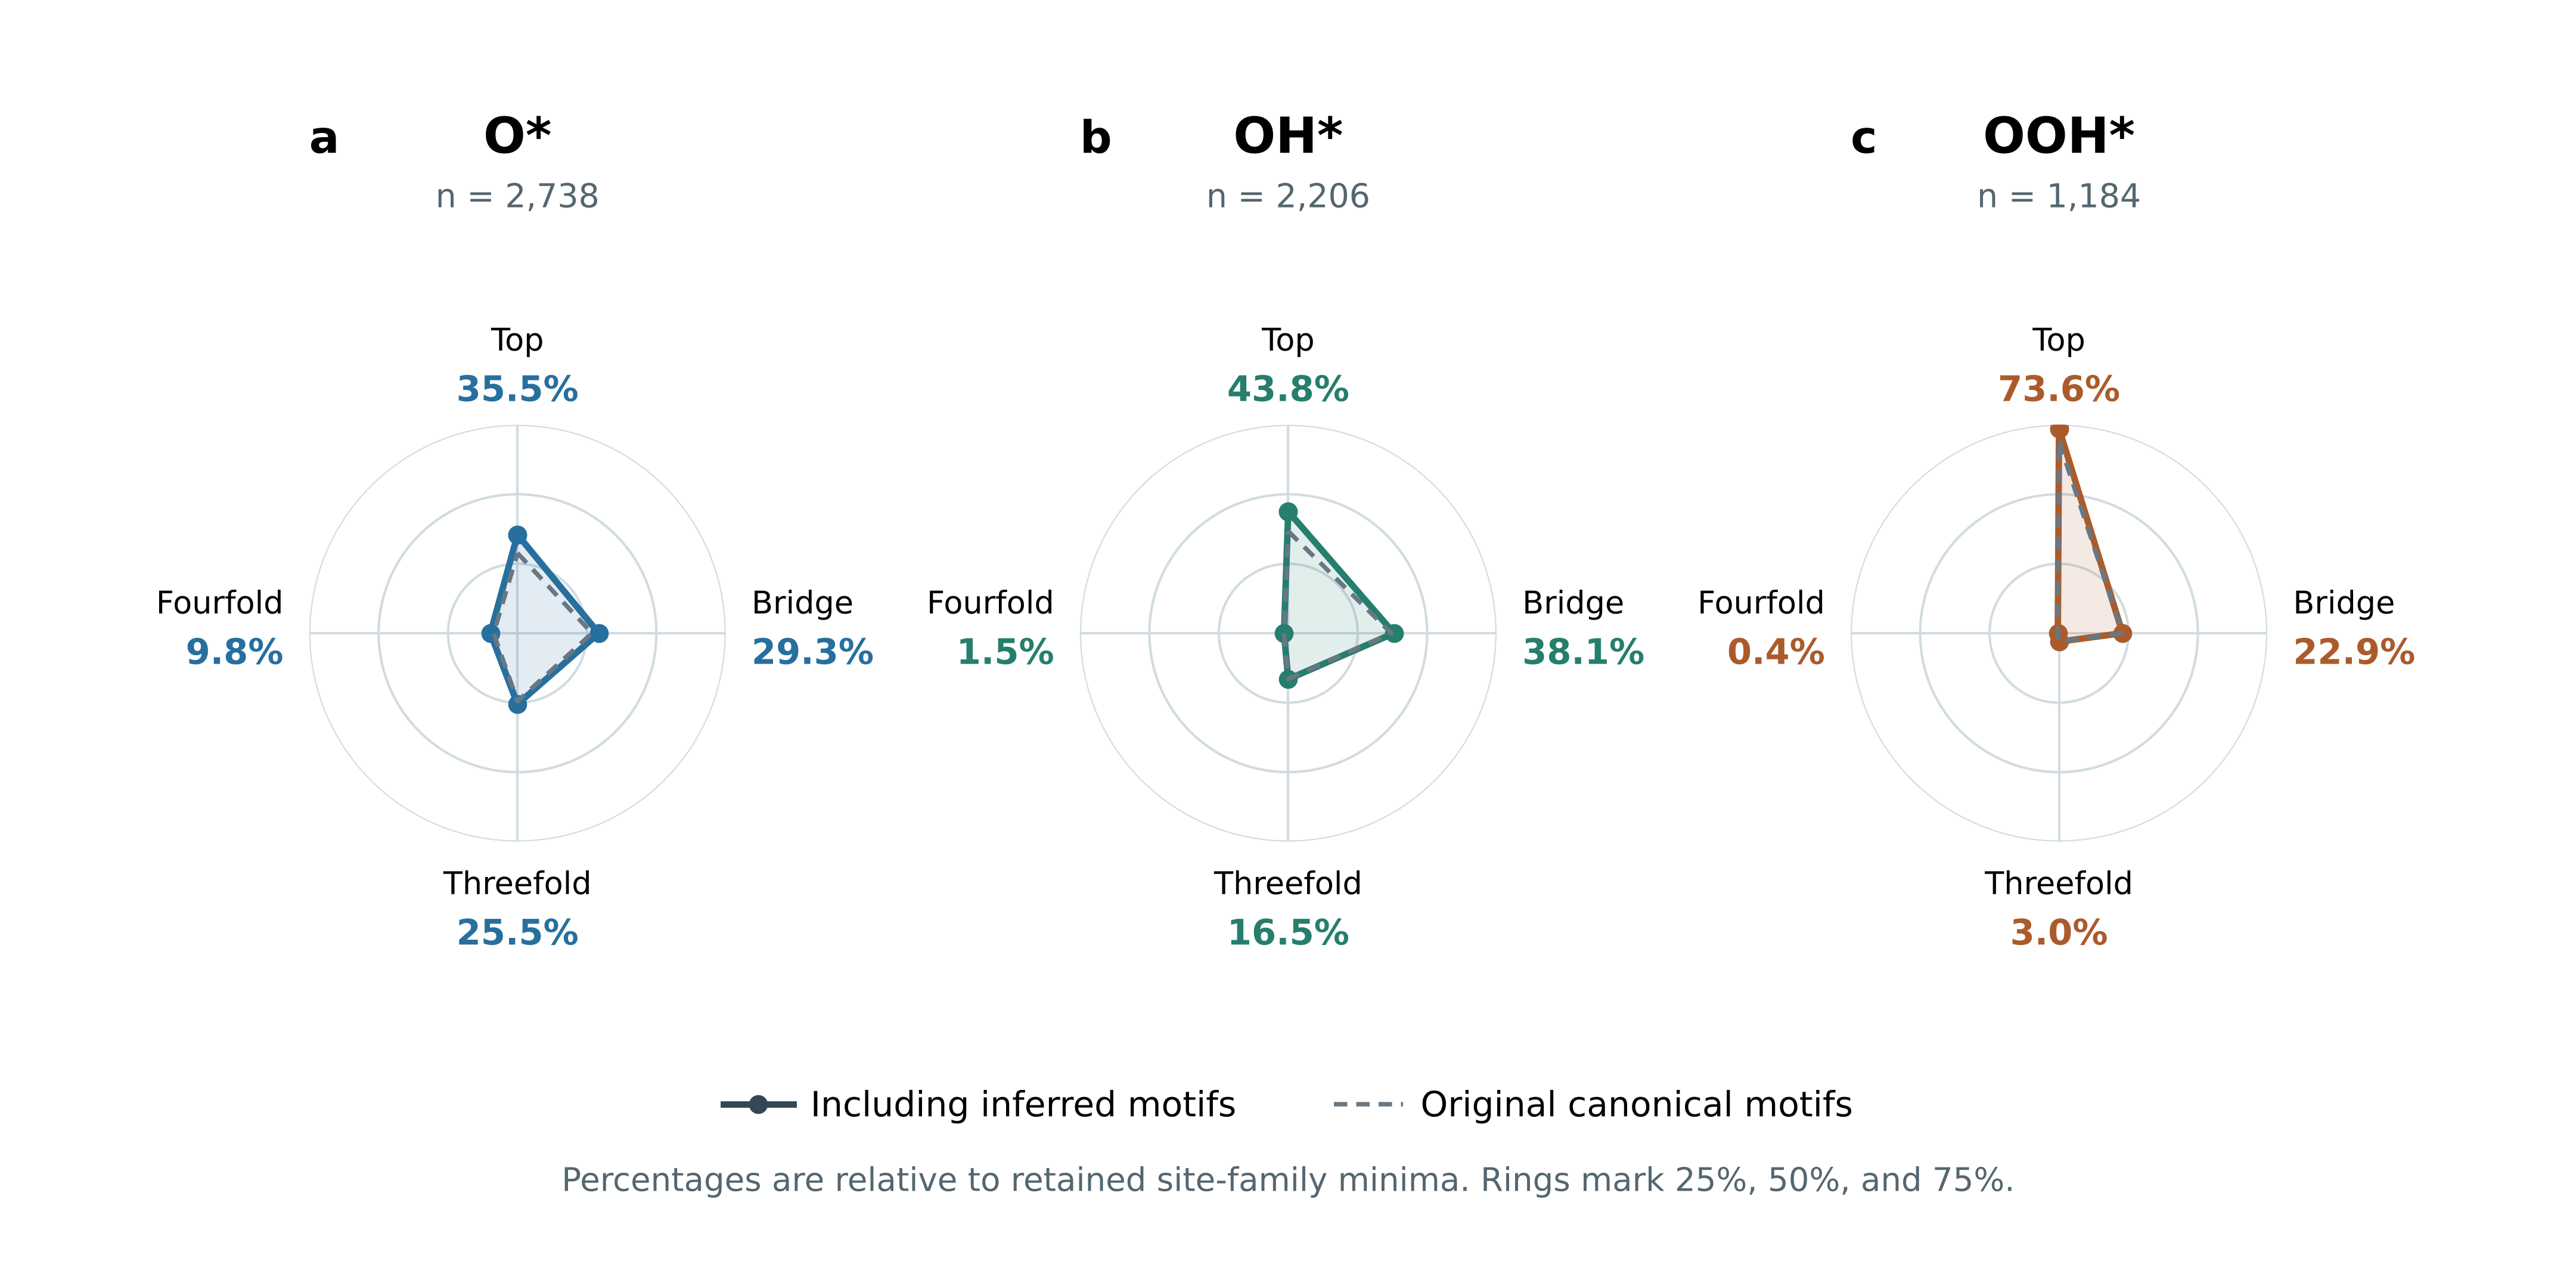

In [8]:
def plot_coordination_radar(totals, original_counts, classified_counts):
    """Use the same linear scale for each intermediate and motif."""
    fig = plt.figure(figsize=(183 / 25.4, 90 / 25.4), facecolor="white")
    grid = fig.add_gridspec(
        1, 3, left=0.12, right=0.88, bottom=0.25, top=0.75, wspace=0.85,
    )
    axes = [fig.add_subplot(grid[index], projection="polar") for index in range(3)]
    angles = np.arange(4) * (np.pi / 2)
    closed_angles = np.r_[angles, angles[0]]
    adsorbate_colors = {"O": "#276F9F", "OH": "#267E6D", "OOH": "#AB5B2B"}
    reference_color = "#677884"
    fig.canvas.draw()

    for ax, adsorbate, letter in zip(axes, ADSORBATES, "abc"):
        color = adsorbate_colors[adsorbate]
        canonical = original_counts.loc[adsorbate].to_numpy(dtype=float) * 100 / totals[adsorbate]
        assigned = classified_counts.loc[adsorbate].to_numpy(dtype=float) * 100 / totals[adsorbate]
        classified_profile = np.r_[assigned, assigned[0]]
        ax.set_theta_offset(np.pi / 2)
        ax.set_theta_direction(-1)
        ax.set_ylim(0, 75)
        ax.set_xticks(angles, [])
        ax.set_yticks([25, 50, 75], [])
        ax.grid(color="#D1DCE1", linewidth=0.50)
        ax.spines["polar"].set_visible(False)
        ax.fill(closed_angles, classified_profile, facecolor=color, alpha=0.13, zorder=2)
        ax.plot(
            closed_angles, classified_profile, color=color, linewidth=1.30,
            marker="o", markersize=2.8, zorder=3,
        )
        ax.plot(
            closed_angles, np.r_[canonical, canonical[0]], color=reference_color,
            linewidth=0.90, linestyle=(0, (3, 2)), zorder=4,
        )

        box = ax.get_position()
        cx, cy = (box.x0 + box.x1) / 2, (box.y0 + box.y1) / 2
        fig.text(box.x0, 0.879, letter, fontsize=9, fontweight="bold")
        fig.text(cx, 0.879, f"{adsorbate}*", fontsize=10, fontweight="bold", ha="center")
        fig.text(cx, 0.836, f"n = {totals[adsorbate]:,}", fontsize=6.65, color="#54666F", ha="center")
        label_positions = [
            (cx, box.y1 + 0.065, "center"),
            (box.x1 + 0.010, cy + 0.022, "left"),
            (cx, box.y0 - 0.035, "center"),
            (box.x0 - 0.010, cy + 0.022, "right"),
        ]
        for label, value, (x, y, align) in zip(MOTIFS.values(), assigned, label_positions):
            fig.text(x, y, label, ha=align, va="center", fontsize=6.3)
            fig.text(x, y - 0.039, f"{value:.1f}%", ha=align, va="center",
                     fontsize=7.1, fontweight="bold", color=color)

    handles = [
        mpl.lines.Line2D([], [], color="#334854", linewidth=1.3, marker="o", markersize=2.8,
                         label="Including inferred motifs"),
        mpl.lines.Line2D([], [], color=reference_color, linewidth=0.9, linestyle=(0, (3, 2)),
                         label="Original canonical motifs"),
    ]
    fig.legend(handles=handles, loc="center", bbox_to_anchor=(0.5, 0.126), ncol=2,
               fontsize=7, frameon=False, handletextpad=0.5, columnspacing=2.8)
    fig.text(0.5, 0.060, "Percentages are relative to retained site-family minima. Rings mark 25%, 50%, and 75%.",
             ha="center", fontsize=6.55, color="#54666F")
    return fig


export_figure(plot_coordination_radar(totals, original_counts, classified_counts), "site_motif_radar")

## Oxygen adsorption energy by site motif and contacting element (descriptive statistics)

Bars show the mean EqV2-predicted O* adsorption energy for the original top,
bridge, threefold, and fourfold assignments. Each site-family minimum
contributes once per distinct contacting element. Elements are ordered by the
average of their available motif means. A missing bar indicates that no site-family
minimum in the energy window represents that element–motif combination.

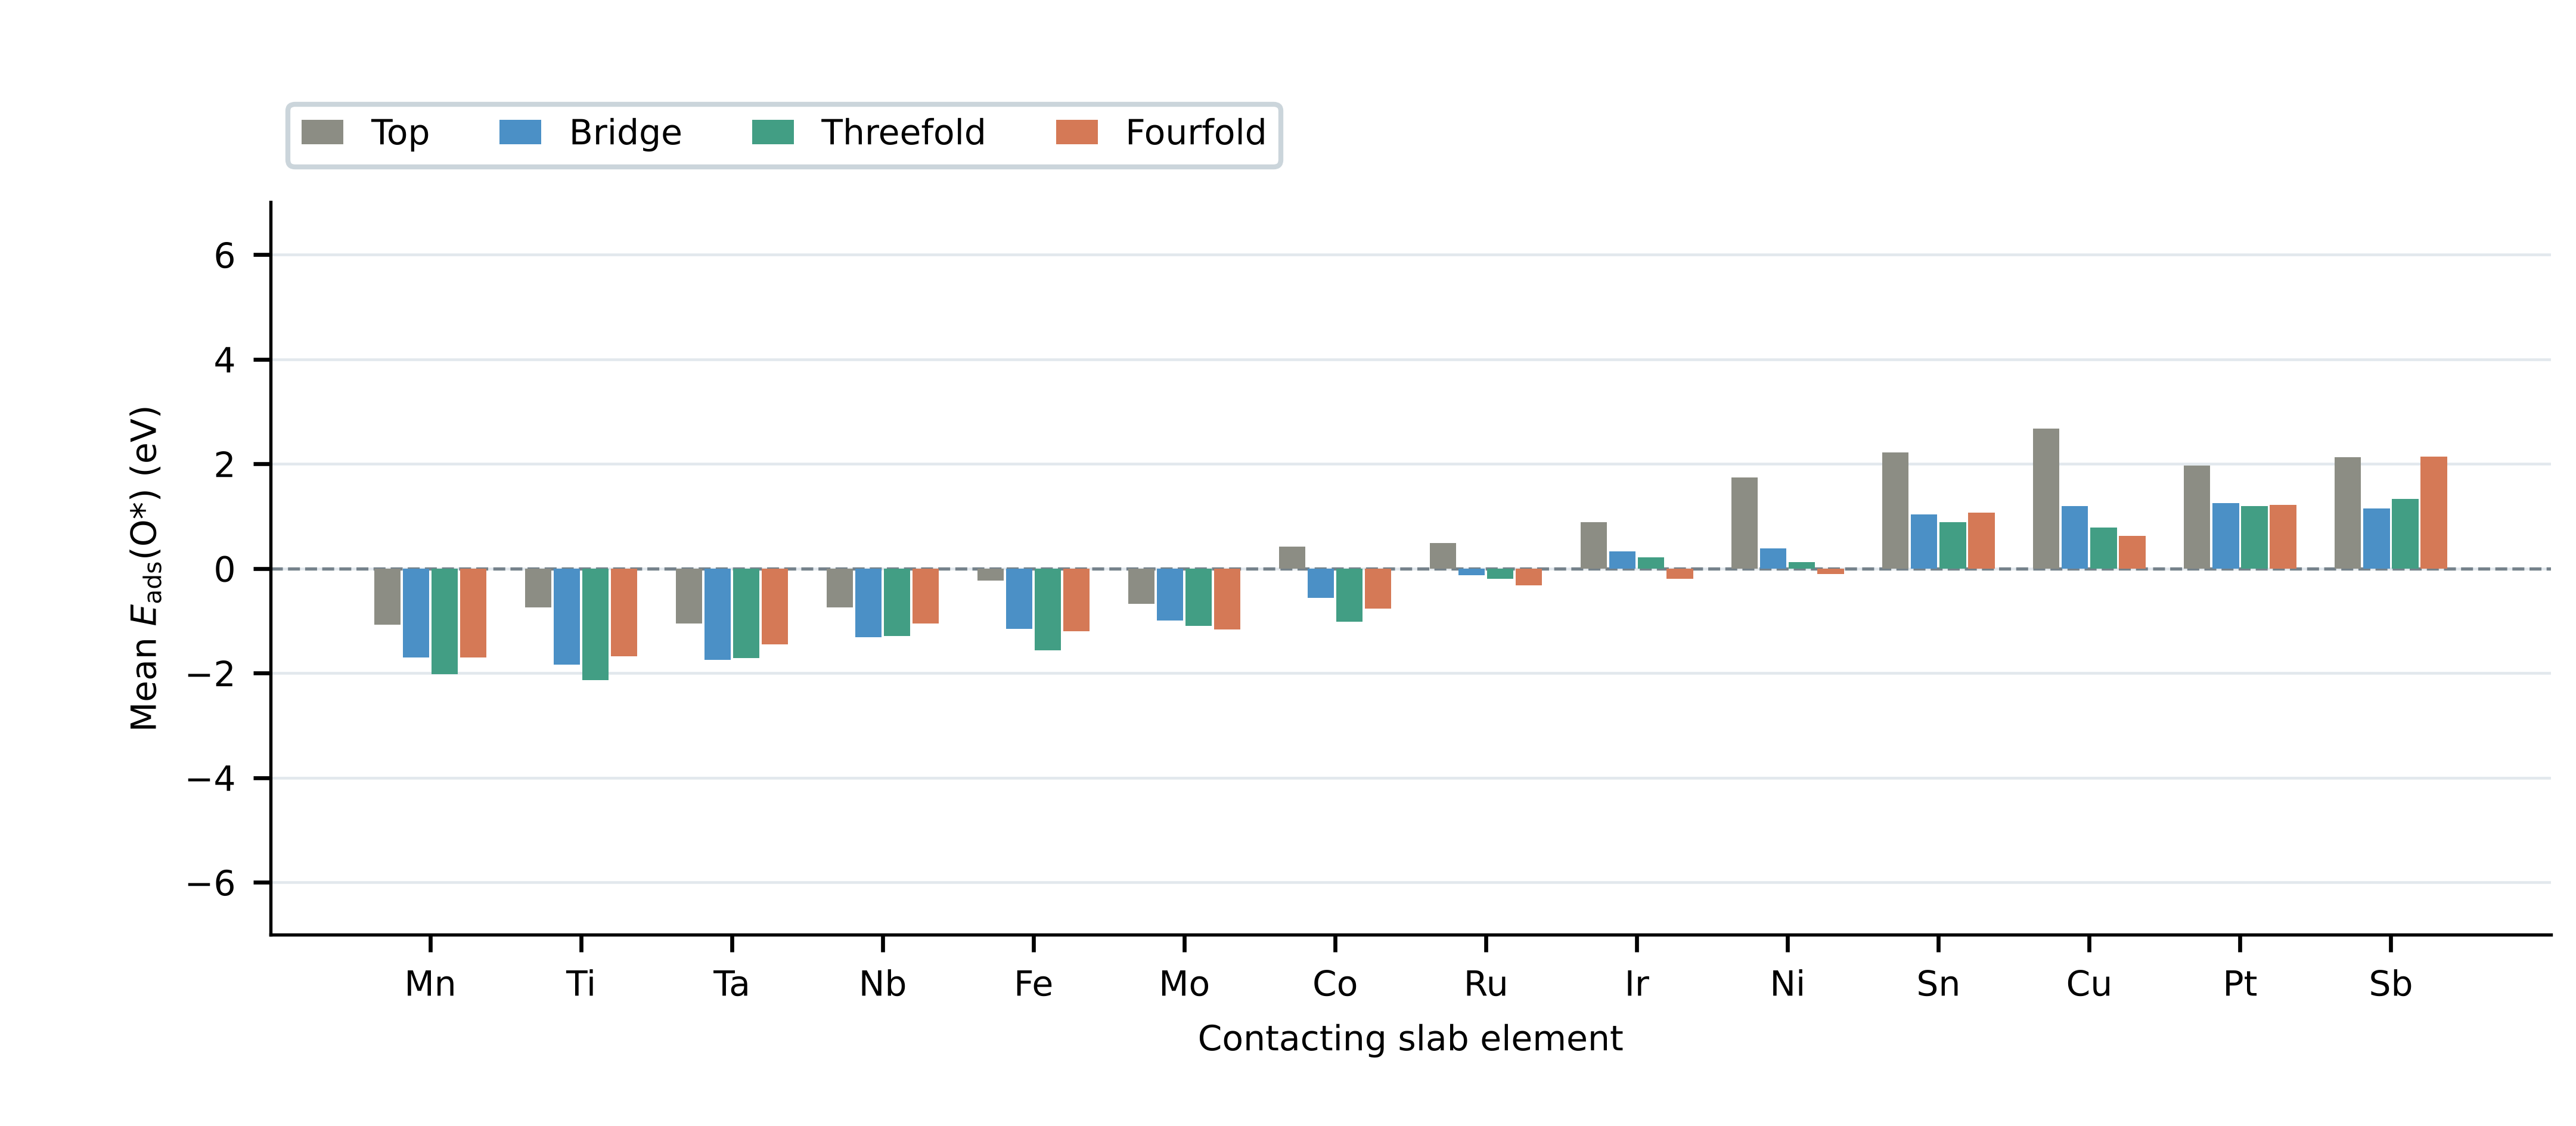

In [9]:
SITE_COLORS = {
    "top": "#8C8D84", "bridge": "#4B90C6",
    "3-fold": "#429E84", "4-fold": "#D57956",
}

oxygen_contacts = element_contacts.loc[element_contacts["adsorbate"].eq("O")]
oxygen_canonical = oxygen_contacts.loc[oxygen_contacts["site_type"].isin(MOTIFS)]
site_breakdown = oxygen_canonical.groupby(["element", "site_type"], as_index=False).agg(
    n_family_minima=(ENERGY, "size"),
    mean_adsorption_energy_eV=(ENERGY, "mean"),
)
site_breakdown.to_csv(OUTPUT_DIR / "oxygen_adsorption_by_site_motif_source_data.csv", index=False)
bars = (
    site_breakdown.pivot(index="element", columns="site_type", values="mean_adsorption_energy_eV")
    .reindex(columns=list(MOTIFS))
)
bars = bars.loc[bars.mean(axis=1).sort_values(kind="stable").index]

fig, ax = plt.subplots(figsize=(183 / 25.4, 80 / 25.4))
fig.subplots_adjust(left=0.105, right=0.99, bottom=0.17, top=0.82)
positions = np.arange(len(bars))
bar_width = 0.19
for index, motif in enumerate(MOTIFS):
    ax.bar(
        positions + (index - 1.5) * bar_width, bars[motif], width=bar_width * 0.92,
        color=SITE_COLORS[motif], label=MOTIFS[motif], zorder=3,
    )
ax.set_xticks(positions, labels=bars.index)
ax.set_ylim(*ENERGY_WINDOW)
ax.set_xlabel("Contacting slab element")
ax.set_ylabel(r"Mean $E_{\mathrm{ads}}$(O*) (eV)")
ax.set_axisbelow(True)
ax.grid(axis="y", color="#E2E8ED", linewidth=0.55)
ax.axhline(0, color="#75828B", linestyle="--", linewidth=0.65)
ax.legend(
    loc="lower left", bbox_to_anchor=(0, 1.025), ncols=4,
    frameon=True, edgecolor="#CBD5DB", framealpha=1, handlelength=1.2,
)
export_figure(fig, "oxygen_adsorption_by_site_motif")

## Pauling electronegativity and median oxygen adsorption energy (descriptive statistics)

Each point gives the median EqV2-predicted O* adsorption energy among the
site-family minima in the window that contact the labeled element. Marker area
is proportional to the number of contributing minima. The dashed line is an
unweighted linear fit across elements. Pearson's $r$ is a descriptive
measure of this association. Mixed-element minima can contribute to several
element medians. Pauling electronegativities are standard tabulated values.
The vertical limits follow the plotted medians. All contributing minima are
selected using the shared −7 to +7 eV energy window.

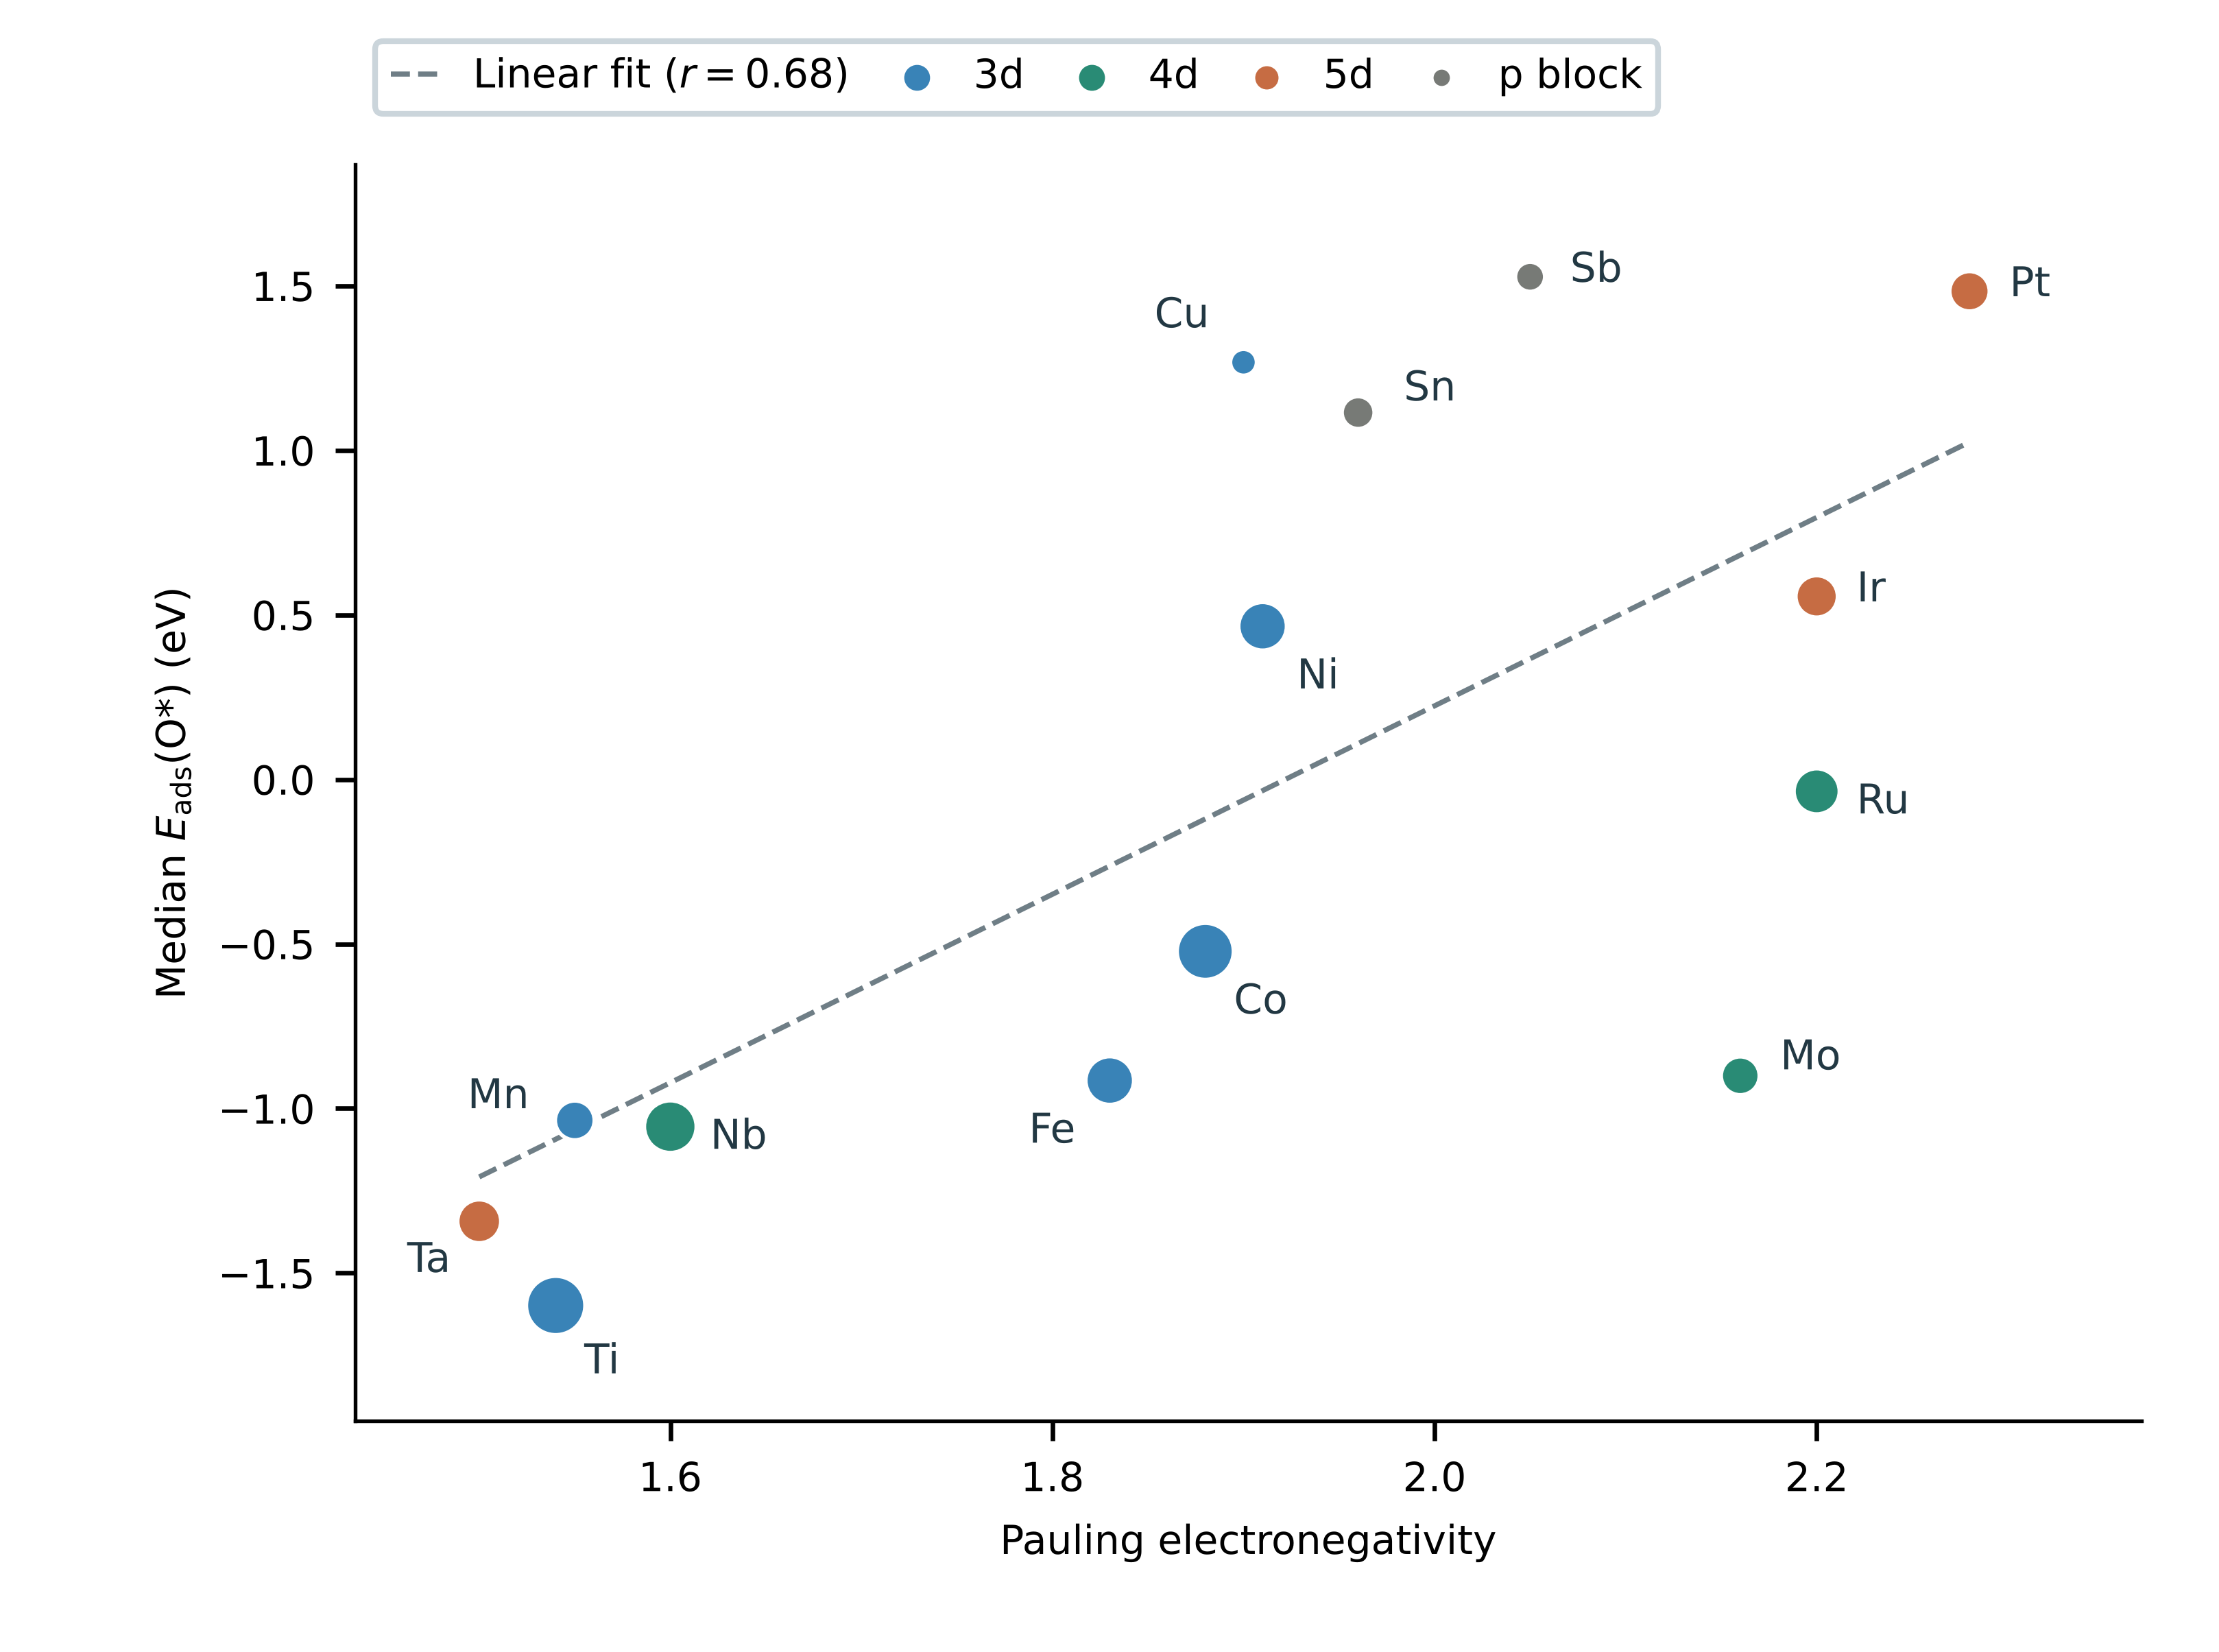

In [10]:
PAULING_ELECTRONEGATIVITY = {
    "Ti": 1.54, "Mn": 1.55, "Fe": 1.83, "Co": 1.88, "Ni": 1.91, "Cu": 1.90,
    "Nb": 1.60, "Mo": 2.16, "Ru": 2.20,
    "Ta": 1.50, "Ir": 2.20, "Pt": 2.28, "Sn": 1.96, "Sb": 2.05,
}
SERIES_COLORS = {"3d": "#3983B7", "4d": "#298B75", "5d": "#C66C43", "p block": "#777A76"}
series_by_element = {element: series for series, members in ELEMENT_GROUPS.items() for element in members}

en_summary = oxygen_contacts.groupby("element", as_index=False).agg(
    n_family_minima=(ENERGY, "size"),
    median_adsorption_energy_eV=(ENERGY, "median"),
)
en_summary["pauling_electronegativity"] = en_summary["element"].map(PAULING_ELECTRONEGATIVITY)
en_summary["element_series"] = en_summary["element"].map(series_by_element)
en_summary.to_csv(OUTPUT_DIR / "oxygen_adsorption_vs_electronegativity_source_data.csv", index=False)

x = en_summary["pauling_electronegativity"].to_numpy(dtype=float)
y = en_summary["median_adsorption_energy_eV"].to_numpy(dtype=float)
n = en_summary["n_family_minima"].to_numpy()
fig, ax = plt.subplots(figsize=(137 / 25.4, 102 / 25.4))
fig.subplots_adjust(left=0.16, right=0.965, bottom=0.14, top=0.90)
slope, intercept = np.polyfit(x, y, 1)
fit_x = np.linspace(x.min(), x.max(), 200)
pearson_r = np.corrcoef(x, y)[0, 1]
ax.plot(
    fit_x, slope * fit_x + intercept, linestyle="--", color="#6F7E86", linewidth=0.9,
    label=rf"Linear fit ($r={pearson_r:.2f}$)",
)
for series, color in SERIES_COLORS.items():
    use = en_summary["element_series"].eq(series)
    ax.scatter(
        x[use], y[use], s=0.23 * n[use], label=series, color=color,
        edgecolor="white", linewidth=0.65, zorder=4,
    )
label_offsets = {
    "Ta": (-5, -7), "Ti": (5, -10), "Mn": (-8, 4), "Nb": (7, -2),
    "Fe": (-6, -9), "Co": (5, -9), "Cu": (-6, 8), "Ni": (6, -9), "Sn": (8, 4),
    "Mo": (7, 3), "Ru": (7, -2), "Ir": (7, 1), "Pt": (7, 1), "Sb": (7, 1),
}
for row in en_summary.itertuples(index=False):
    dx, dy = label_offsets[row.element]
    ax.annotate(
        row.element, (row.pauling_electronegativity, row.median_adsorption_energy_eV),
        xytext=(dx, dy), textcoords="offset points", color="#223843",
        ha="right" if dx < 0 else "left", va="center", fontsize=7.2,
    )
ax.set_xlim(x.min() - 0.065, x.max() + 0.09)
ax.set_ylim(y.min() - 0.35, y.max() + 0.34)
ax.set_xlabel("Pauling electronegativity")
ax.set_ylabel(r"Median $E_{\mathrm{ads}}$(O*) (eV)")
ax.set_axisbelow(True)
ax.legend(
    loc="lower left", bbox_to_anchor=(0, 1.025), ncols=5, frameon=True,
    borderpad=0.4, edgecolor="#CBD5DB", framealpha=1,
    columnspacing=1.05, handlelength=1.25, markerscale=0.65,
)
export_figure(fig, "oxygen_adsorption_vs_electronegativity")

## Adsorption-energy distributions by contacting element (descriptive statistics)

The ridgelines show binned EqV2-predicted adsorption-energy distributions for
each contacting element and intermediate. Elements are ordered by their median
energy within each panel. Short dashed markers show the medians, and the gray
dotted line marks zero. Each ridge is scaled to its own maximum bin count to
show the distribution shape. Unscaled counts are available in the figure's CSV.

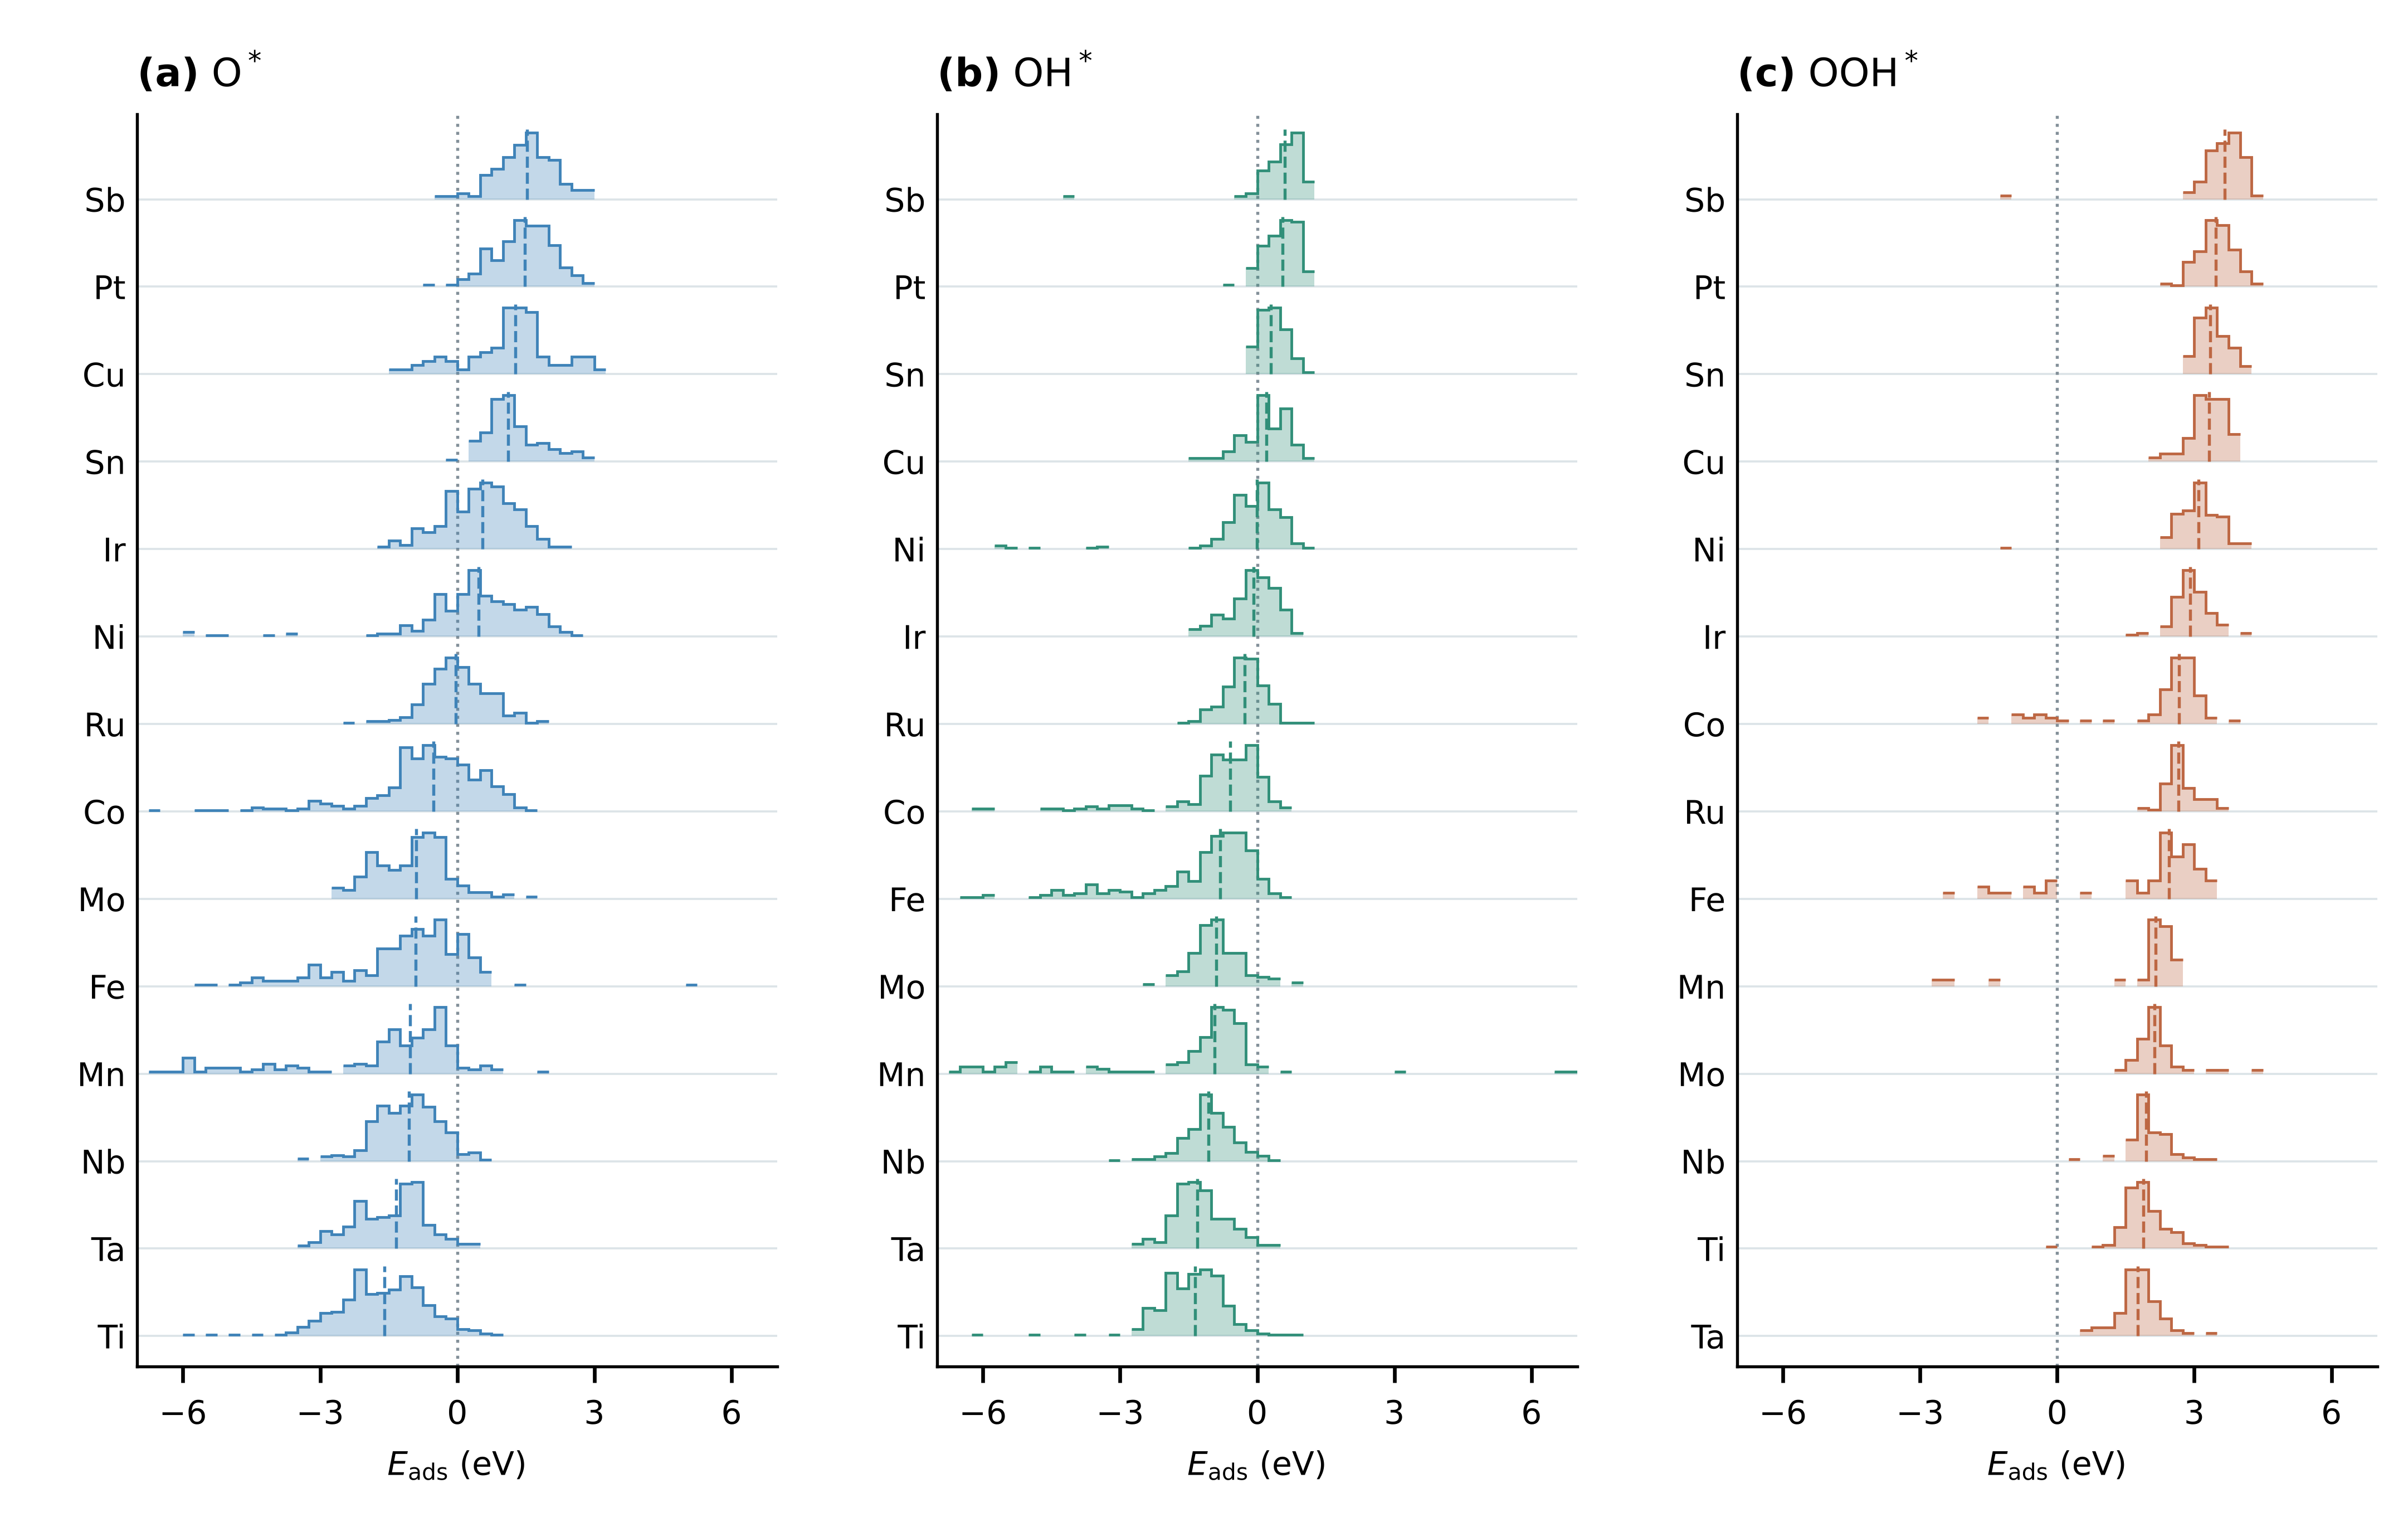

In [11]:
ridge_bins = np.linspace(*ENERGY_WINDOW, 57)
ridge_colors = {"O": "#3F83B8", "OH": "#318F79", "OOH": "#BD6743"}
fig, axes = plt.subplots(1, 3, figsize=(183 / 25.4, 116 / 25.4))
fig.subplots_adjust(left=0.057, right=0.987, bottom=0.105, top=0.925, wspace=0.25)
ridge_source = []

for ax, adsorbate, letter in zip(axes, ADSORBATES, "abc"):
    color = ridge_colors[adsorbate]
    grouped = element_contacts.loc[element_contacts["adsorbate"].eq(adsorbate)].groupby("element")[ENERGY]
    medians = grouped.median().sort_values(kind="stable")
    for baseline, (element, median) in enumerate(medians.items()):
        values = grouped.get_group(element).to_numpy()
        counts, edges = np.histogram(values, bins=ridge_bins)
        profile = baseline + 0.76 * counts / counts.max()
        ax.axhline(baseline, color="#DCE4E8", linewidth=0.45, zorder=0)
        ax.stairs(profile, edges, baseline=baseline, fill=True, color=color, alpha=0.31, linewidth=0)
        ax.stairs(np.where(counts > 0, profile, np.nan), edges,
                  baseline=None, color=color, linewidth=0.58)
        ax.vlines(median, baseline, baseline + 0.80, color=color, linestyle="--", linewidth=0.65)
        ridge_source.append(pd.DataFrame({
            "adsorbate": adsorbate, "element": element, "n_family_minima": len(values),
            "median_adsorption_energy_eV": median, "bin_left_eV": edges[:-1],
            "bin_right_eV": edges[1:], "bin_count": counts,
        }))
    ax.axvline(0, color="#839099", linestyle=":", linewidth=0.65, zorder=0)
    ax.set_title(rf"$\mathbf{{({letter})}}$ {adsorbate}$^*$", loc="left")
    ax.set_yticks(range(len(medians)), labels=medians.index)
    ax.tick_params(axis="y", length=0, pad=2.5)
    ax.set(xlim=ENERGY_WINDOW, ylim=(-0.35, len(medians) - 0.03),
           xlabel=r"$E_{\mathrm{ads}}$ (eV)")
    ax.set_xticks([-6, -3, 0, 3, 6])

pd.concat(ridge_source, ignore_index=True).to_csv(
    OUTPUT_DIR / "adsorption_energy_ridgelines_source_data.csv", index=False,
)
export_figure(fig, "adsorption_energy_ridgelines")

## Notes for reuse

- All statistics refer to EqV2 predictions on the ML-relaxed geometries. The DFT
  validation of the global minima is described in the article and its Supporting
  Information.
- Site motifs, coordinating elements, and the `review` flag come from the periodic
  first-shell detector of the screening notebook. The radar profiles additionally
  infer motifs for off-center and irregular geometries, and the reassignment table
  records every inferred case.
- Mn-, Fe-, and Co-containing surfaces show long tails toward strongly negative
  energies. As discussed in the article, these tails should be interpreted cautiously
  because the non-spin-polarized OC20 training data can introduce systematic errors
  for magnetic surfaces.